# MATERNA-AI: Multi-Tier Clinical Decision Support System for Early Preeclampsia Prediction & Risk Trajectory
**UTS Data Mining — A11.2024.16055 — Nayyara Rauf Ghani Al Khayri**

---
Notebook ini mengimplementasikan secara *end-to-end* seluruh tahapan dalam **Product Requirements Document (PRD v2.5)** serta menyajikan **10 Visualisasi Evaluasi Model Standar Publikasi & Dashboard Medis**:
1. **Automated Clinical Data Auditing & Boundary Validator**: Validasi logika obstetrik (`gravida == 1` $\rightarrow$ `nullipara = 1`), validasi hemodinamik (`Diastolik < Sistolik`), serta *Smart Imputation* (median per usia kehamilan untuk numerik, modus untuk kategorikal).
2. **Seleksi Fitur ACRFS (*Aggregated Coefficient Ranking Feature Selection*)**: Kombinasi korelasi $|r|$ Pearson, *Mutual Information*, dan statistik $\chi^2$.
3. **Dual-Engine Multi-Tier Screening & Longitudinal Trajectory Tracking**:
   - **Mode Tier 1 (Faskes Primer)**: Variabel klinis dasar + $\text{MAP}$ & $\Delta\text{MAP}$ tanpa laboratorium.
   - **Mode Tier 2 (RSUD Rujukan)**: Integrasi biomarker organ target (Proteinuria, PCR urin, Trombosit, SGOT/SGPT, Kreatinin, Asam Urat, dan Doppler UtAPI).
4. **Multi-Model Pipeline dengan SMOTE-NC & Optimasi Hyperparameter (`GridSearchCV`)**:
   - 4 Model Inti (`KNN`, `Naive Bayes`, `Decision Tree`, `SVM`) + 2 Model Ensemble (`XGBoost`, `LightGBM`).
   - Penanganan *class imbalance* menggunakan **SMOTE-NC** (khusus pada *training fold*) dan `class_weight='balanced'`.
5. **10 Visualisasi Evaluasi Model Klinis (`dpi=300`)**: Mencakup distribusi kelas, perbandingan akurasi, *Stratified 5-Fold Cross-Validation*, *Precision-Recall-F1*, *ROC-AUC*, kompleksitas waktu komputasi, peringkat fitur *ACRFS*, *Feature Correlation Heatmap*, *Confusion Matrix* model terbaik, serta *ROC & Precision-Recall Curves*.

In [ ]:
import os
import sys
import json
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# Pastikan root proyek berada di sys.path dan folder reports/ tersedia
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

os.makedirs('reports', exist_ok=True)
os.makedirs(PROJECT_ROOT / 'reports', exist_ok=True)

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)
from materna_ai.config import ALL_FEATURES, TIER1_ENGINE_FEATURES, FEATURE_CLINICAL_META
from materna_ai.feature_engineering import compute_acrfs_feature_ranking

# Konfigurasi global styling grafik standar publikasi medis
plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'font.family': 'sans-serif',
    'axes.edgecolor': '#CCCCCC',
    'axes.linewidth': 0.8,
    'axes.titleweight': 'bold',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9.5,
})
sns.set_theme(style='whitegrid')

def save_and_sync_figure(filename: str):
    """Menyimpan grafik ke folder reports/ dengan resolusi tinggi (dpi=300)."""
    local_path = Path('reports') / filename
    root_path = PROJECT_ROOT / 'reports' / filename
    plt.savefig(local_path, dpi=300, bbox_inches='tight', facecolor='white')
    if local_path.resolve() != root_path.resolve():
        plt.savefig(root_path, dpi=300, bbox_inches='tight', facecolor='white')

df = pd.read_csv(PROJECT_ROOT / 'data' / 'preeclampsia_clinical_dataset.csv')
print(f'Dataset klinis berhasil dimuat: {df.shape[0]} pasien unik x {df.shape[1]} atribut')
df.head()

Dataset klinis berhasil dimuat: 1200 pasien unik x 38 atribut


,patient_id,faskes_origin,gestational_age_weeks,maternal_age,gravida,parity,nullipara,preg_interval_yrs,prev_pe_history,family_htn_history,...,sgot_ast_u_l,sgpt_alt_u_l,uric_acid_mg_dl,utapi_doppler,preeclampsia_subtype_code,preeclampsia_subtype,preeclampsia_diagnosis,proteinuria_ordinal,faskes_code,comorbid_htn_dm
0,MAT-20260001,RSUD_Rujukan,33,29,2,1,0,3.4,1,0,...,23,21,4.5,1.11,0,Normal,0,0,2,0
1,MAT-20260002,Puskesmas_Induk,34,32,3,2,0,6.2,0,0,...,17,34,4.3,1.00,1,Late_Onset_PE,1,1,1,1
2,MAT-20260003,Puskesmas_Pembantu,28,32,1,0,1,0.0,0,0,...,24,25,5.3,1.25,0,Normal,0,0,0,0
3,MAT-20260004,RSUD_Rujukan,25,27,5,4,0,4.6,0,1,...,25,13,4.2,0.91,0,Normal,0,0,2,1
4,MAT-20260005,Puskesmas_Induk,27,32,5,4,0,5.2,0,0,...,31,33,5.9,1.18,0,Normal,0,0,1,0


## 1. Statistik Deskriptif, Seleksi Fitur ACRFS, & Distribusi Subtipe Preeklamsia
Memeriksa proporsi kelas target biner (`preeclampsia_diagnosis`), target stratifikasi 3-kelas (`preeclampsia_subtype`), serta peringkat fitur prediktif hasil metode **ACRFS (*Aggregated Coefficient Ranking Feature Selection*)**.

In [ ]:
print('=== Distribusi Diagnosis Preeklamsia (Biner: 0=Normal, 1=Preeklamsia) ===')
print(df['preeclampsia_diagnosis'].value_counts(dropna=False))

print('\n=== Distribusi Subtipe Preeklamsia (Multi-Kelas) ===')
print(df['preeclampsia_subtype'].value_counts(dropna=False))

acrfs_path = PROJECT_ROOT / 'logs' / 'acrfs_feature_ranking.csv'
acrfs_df = pd.read_csv(acrfs_path) if acrfs_path.exists() else compute_acrfs_feature_ranking(df)
print('\n=== Top 10 Fitur Prediktif Berdasarkan ACRFS (Pearson |r| + Mutual Information + Chi-Square) ===')
acrfs_df.head(10)[['rank', 'feature', 'clinical_label', 'tier_group', 'pearson_abs', 'mutual_info', 'chi2_stat', 'acrfs_score']]

=== Distribusi Diagnosis Preeklamsia (Biner: 0=Normal, 1=Preeklamsia) ===
preeclampsia_diagnosis
0    840
1    360
Name: count, dtype: int64

=== Distribusi Subtipe Preeklamsia (Multi-Kelas) ===
preeclampsia_subtype
Normal            840
Late_Onset_PE     216
Early_Onset_PE    144
Name: count, dtype: int64

=== Top 10 Fitur Prediktif Berdasarkan ACRFS (Pearson |r| + Mutual Information + Chi-Square) ===


,rank,feature,clinical_label,tier_group,pearson_abs,mutual_info,chi2_stat,acrfs_score
0,1,proteinuria_ordinal,Proteinuria Dipstick,Tier 2 (Biomarker & Doppler),0.7019,0.2694,246.9408,0.9008
1,2,delta_map,Lonjakan MAP (ΔMAP),Trajectory ANC,0.7390,0.3569,52.1857,0.7370
2,3,urine_pcr,Rasio Protein/Kreatinin Urin,Tier 2 (Biomarker & Doppler),0.6490,0.2920,64.5415,0.6512
3,4,map_mmhg,Mean Arterial Pressure (MAP),Tier 1 (Klinis Dasar),0.6728,0.2922,34.2206,0.6214
4,5,delta_sbp,Lonjakan Sistolik (ΔSBP),Trajectory ANC,0.6338,0.2423,31.4869,0.5528
5,6,sgot_ast_u_l,Enzim Hepar SGOT (AST),Tier 2 (Biomarker & Doppler),0.5886,0.2311,53.8042,0.5515
6,7,delta_dbp,Lonjakan Diastolik (ΔDBP),Trajectory ANC,0.6237,0.2353,28.0101,0.5369
7,8,utapi_doppler,Doppler Arteri Uterina (UtAPI),Tier 2 (Biomarker & Doppler),0.5944,0.2306,38.7822,0.5335
8,9,sgpt_alt_u_l,Enzim Hepar SGPT (ALT),Tier 2 (Biomarker & Doppler),0.5706,0.2191,44.9700,0.5200
9,10,systolic_bp,Tensi Sistolik,Tier 1 (Klinis Dasar),0.5706,0.2263,28.0750,0.5039


## 2. Evaluasi Komparatif Model & Penyusunan Tabel `evaluation_results.csv`
Memuat artefak model dari direktori `models/`, mengevaluasi kinerja pada *hold-out test set* (`20%` stratified) serta *Stratified 5-Fold Cross-Validation* pada *training set* (`80%`), kemudian menyimpan hasil evaluasi ke `reports/evaluation_results.csv`.

In [ ]:
X = df[ALL_FEATURES].copy()
y = df['preeclampsia_diagnosis'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

with open(PROJECT_ROOT / 'logs' / 'metrics_summary.json', 'r', encoding='utf-8') as f:
    metrics_summary = json.load(f)

core_model_files = [
    ('KNN', 'knn_model.joblib'),
    ('Naive Bayes', 'naive_bayes_model.joblib'),
    ('Decision Tree', 'decision_tree_model.joblib'),
    ('SVM', 'svm_model.joblib'),
]

loaded_models = {}
eval_records = []

for model_name, fname in core_model_files:
    mdl = joblib.load(PROJECT_ROOT / 'models' / fname)
    loaded_models[model_name] = mdl
    y_pred = mdl.predict(X_test)
    y_prob = mdl.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    cv_rec_scores = cross_val_score(mdl, X_train, y_train, cv=cv_strat, scoring='recall')
    cv_acc_scores = cross_val_score(mdl, X_train, y_train, cv=cv_strat, scoring='accuracy')
    meta_info = metrics_summary['models'].get(model_name, {})

    eval_records.append({
        'Model': model_name,
        'Accuracy': round(float(accuracy_score(y_test, y_pred)), 4),
        'CV_Recall': round(float(cv_rec_scores.mean()), 4),
        'CV_Recall_Std': round(float(cv_rec_scores.std()), 4),
        'CV_Accuracy': round(float(cv_acc_scores.mean()), 4),
        'CV_Accuracy_Std': round(float(cv_acc_scores.std()), 4),
        'CV_ROC_AUC': round(float(meta_info.get('cv_roc_auc', roc_auc_score(y_test, y_prob))), 4),
        'Precision': round(float(precision_score(y_test, y_pred)), 4),
        'Recall': round(float(recall_score(y_test, y_pred)), 4),
        'Specificity': round(float(tn / (tn + fp)), 4),
        'F1_Score': round(float(f1_score(y_test, y_pred)), 4),
        'ROC_AUC': round(float(roc_auc_score(y_test, y_prob)), 4),
        'PR_AUC': round(float(average_precision_score(y_test, y_prob)), 4),
        'Training_Time_Sec': round(float(meta_info.get('train_time_sec', 1.0)), 3),
        'TN': int(tn),
        'FP': int(fp),
        'FN': int(fn),
        'TP': int(tp),
    })

eval_df = pd.DataFrame(eval_records)
eval_df.to_csv('reports/evaluation_results.csv', index=False)
eval_df.to_csv(PROJECT_ROOT / 'reports' / 'evaluation_results.csv', index=False)
eval_df.to_csv(PROJECT_ROOT / 'logs' / 'evaluation_results.csv', index=False)

best_model_name = metrics_summary.get('best_model_name', 'Naive Bayes')
print(f'Tabel hasil evaluasi berhasil disimpan ke reports/evaluation_results.csv | Model Terbaik: {best_model_name}')
eval_df

Tabel hasil evaluasi berhasil disimpan ke reports/evaluation_results.csv | Model Terbaik: Naive Bayes


,Model,Accuracy,CV_Recall,CV_Recall_Std,CV_Accuracy,CV_Accuracy_Std,CV_ROC_AUC,Precision,Recall,Specificity,F1_Score,ROC_AUC,PR_AUC,Training_Time_Sec,TN,FP,FN,TP
0,KNN,0.9875,0.9792,0.0068,0.9865,0.0053,0.9996,0.9859,0.9722,0.9940,0.9790,0.9990,0.9979,12.238,167,1,2,70
1,Naive Bayes,0.9917,0.9827,0.0109,0.9885,0.0069,0.9994,0.9861,0.9861,0.9940,0.9861,0.9993,0.9983,3.936,167,1,1,71
2,Decision Tree,0.9208,0.9169,0.0426,0.9281,0.0137,0.9536,0.8442,0.9028,0.9286,0.8725,0.9709,0.8917,18.279,156,12,7,65
3,SVM,0.9917,0.9861,0.0070,0.9906,0.0061,0.9998,1.0000,0.9722,1.0000,0.9859,0.9994,0.9987,18.227,168,0,2,70


---
## 3. Visualisasi Metrik Evaluasi Model Standar Publikasi & Dashboard Medis
Bagian ini menyajikan **10 visualisasi komprehensif (`dpi=300`)** untuk mengevaluasi distribusi kohort klinis, performa komparatif keempat algoritma klasifikasi (`KNN`, `Naive Bayes`, `Decision Tree`, dan `SVM`), efisiensi waktu komputasi `GridSearchCV`, seleksi fitur klinis terpenting, matriks kebingungan (*confusion matrix*) model terbaik, serta kurva *ROC* dan *Precision-Recall*.

### 3.1. Class Distribution (Pie Chart)
Menampilkan proporsi kelas target (`Normal / Non-Preeklamsia` vs `Preeklamsia`) lengkap dengan persentase dan jumlah sampel riil pada kohort pasien maternal ($N = 1.200$).

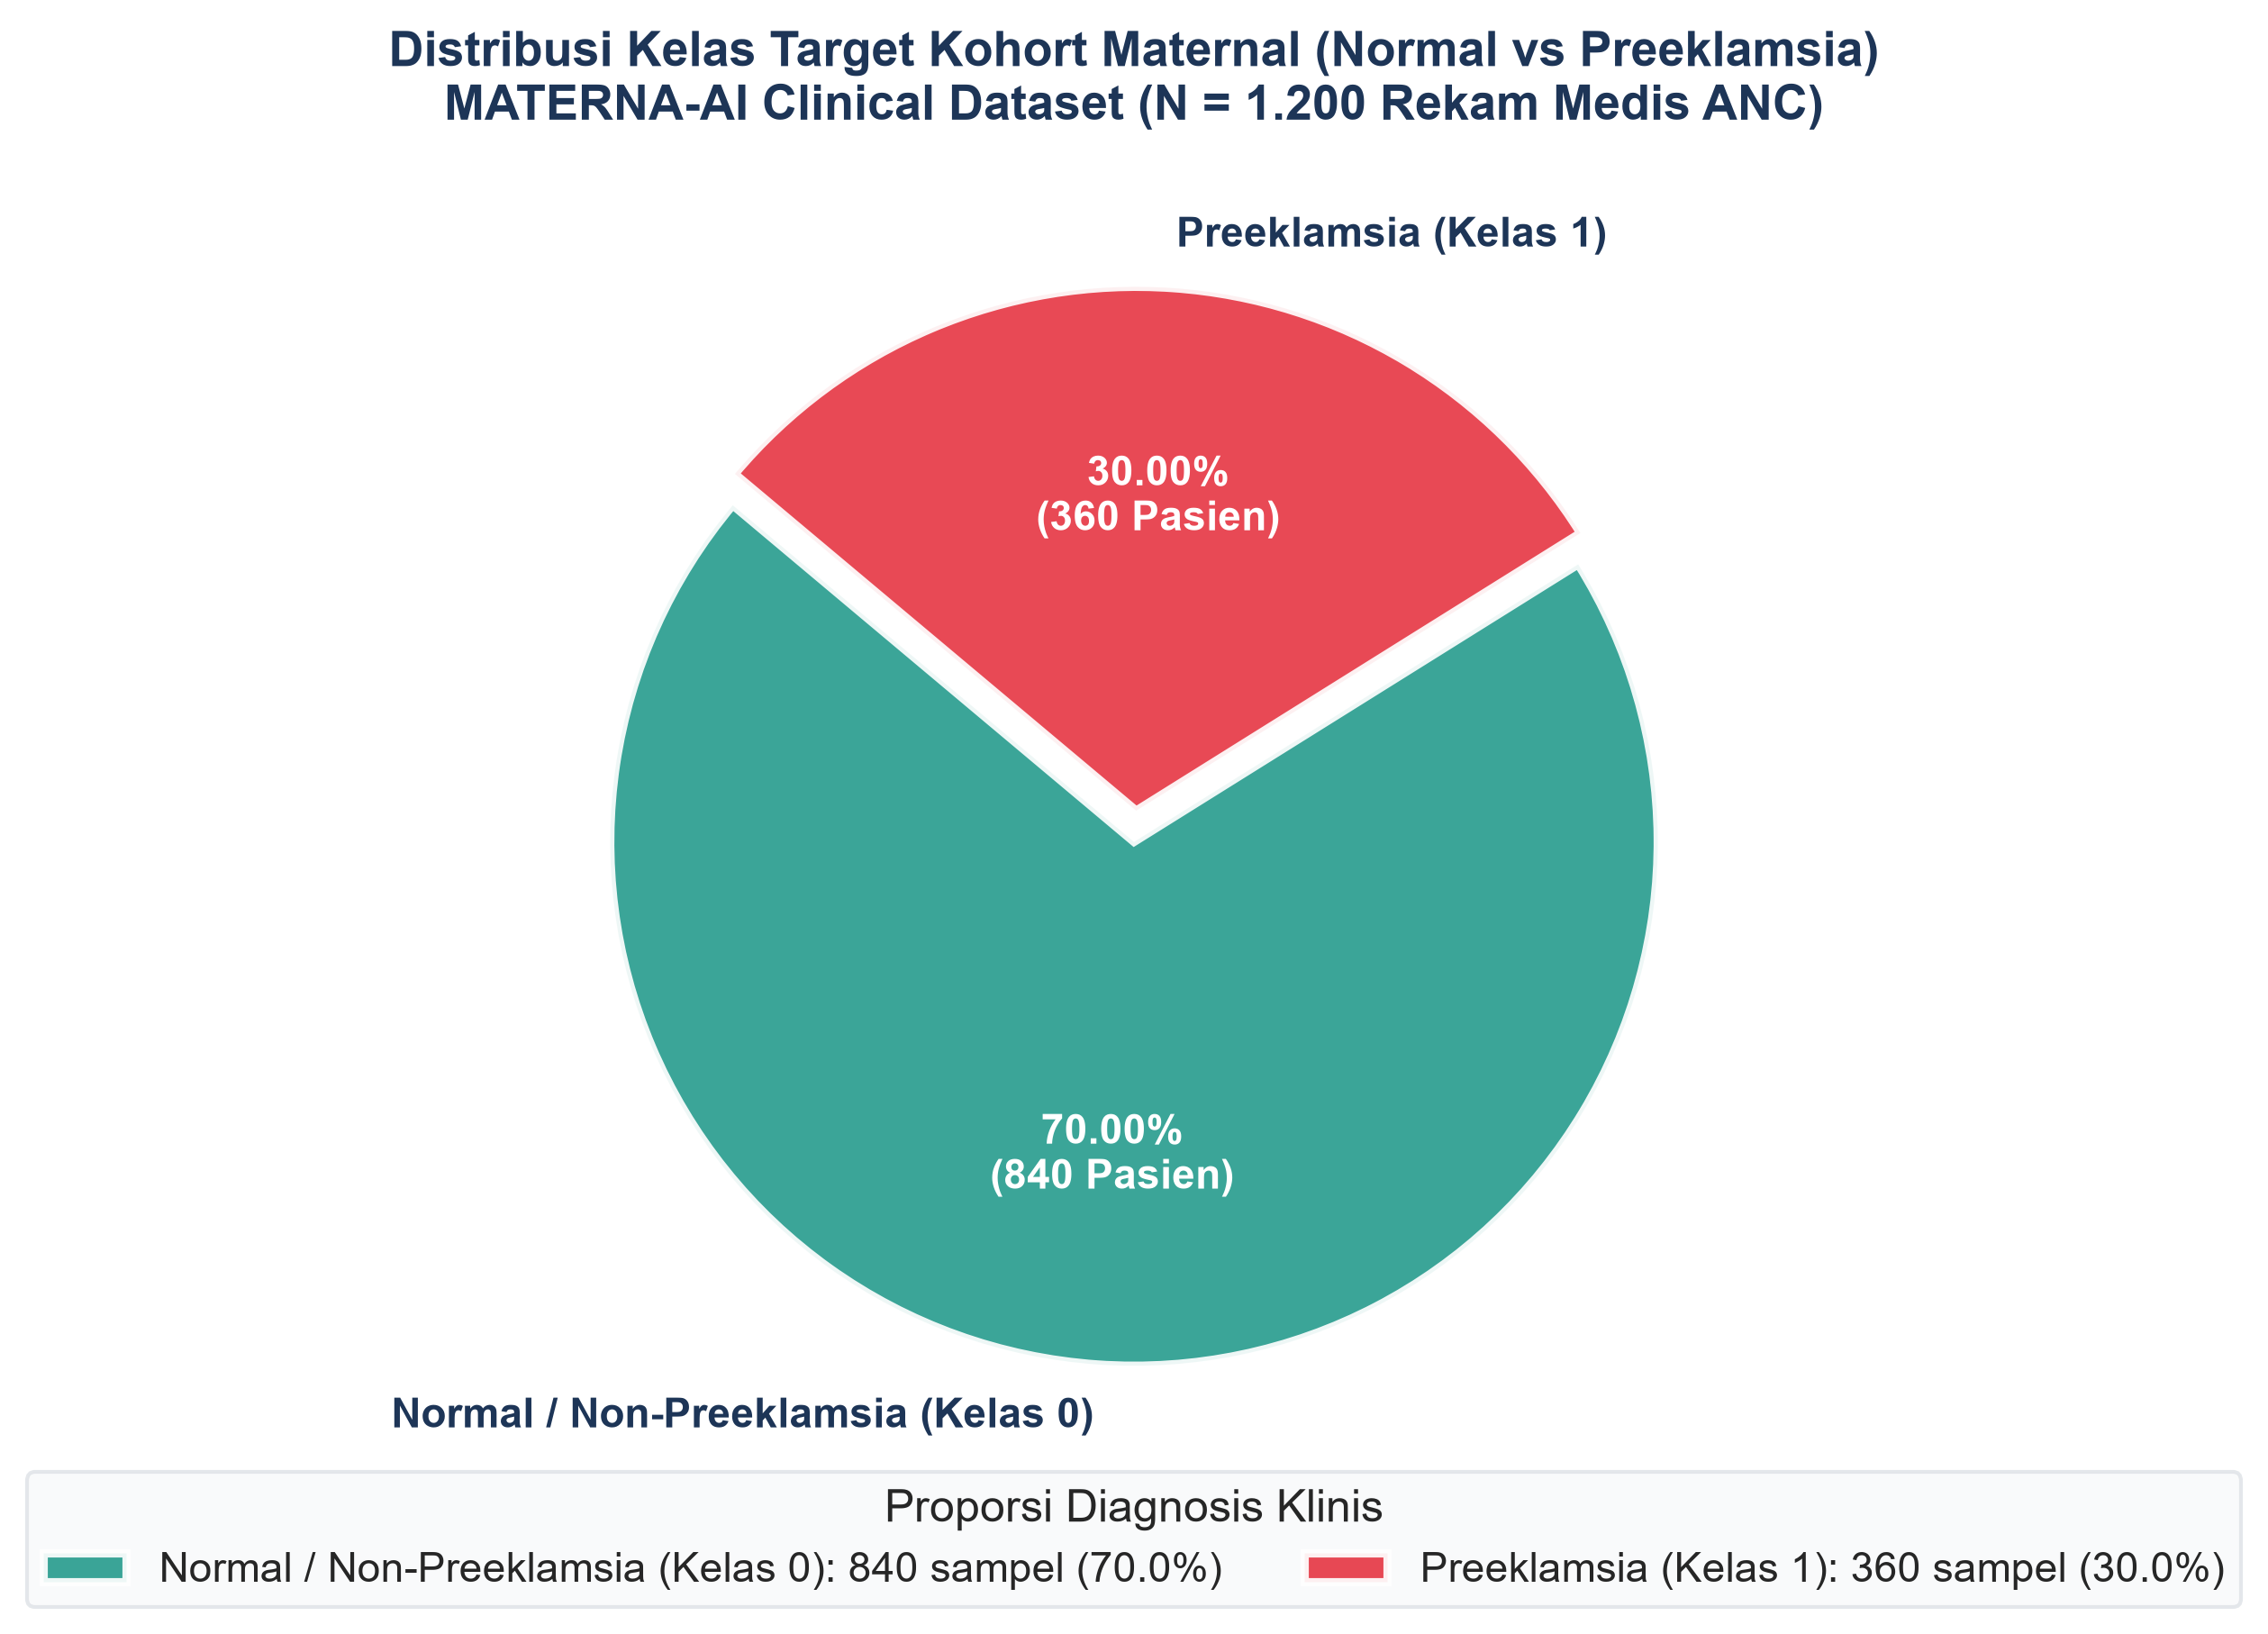

In [ ]:
# 1. Class Distribution (Pie Chart)
class_counts = df['preeclampsia_diagnosis'].value_counts().sort_index()
labels = ['Normal / Non-Preeklamsia (Kelas 0)', 'Preeklamsia (Kelas 1)']
sizes = class_counts.values
palette_pie = ['#2A9D8F', '#E63946']  # Teal Klinis (Normal) & Crimson Medis (Preeklamsia)

def format_pie_label(pct, all_vals):
    absolute = int(round(pct / 100.0 * np.sum(all_vals)))
    return f'{pct:.2f}%\n({absolute:,} Pasien)'

fig, ax = plt.subplots(figsize=(8.5, 6.2), dpi=300)
wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    autopct=lambda pct: format_pie_label(pct, sizes),
    startangle=140,
    colors=palette_pie,
    explode=(0.0, 0.06),
    shadow=False,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2.2, 'alpha': 0.92},
    textprops={'fontsize': 11, 'fontweight': 'bold', 'color': '#1D3557'}
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(11)
    autotext.set_fontweight('bold')

ax.set_title(
    'Distribusi Kelas Target Kohort Maternal (Normal vs Preeklamsia)\n'
    'MATERNA-AI Clinical Dataset (N = 1.200 Rekam Medis ANC)',
    fontsize=13, fontweight='bold', pad=18, color='#1D3557'
)
ax.legend(
    wedges,
    [f'{l}: {s:,} sampel ({s/len(df)*100:.1f}%)' for l, s in zip(labels, sizes)],
    title='Proporsi Diagnosis Klinis',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=True,
    facecolor='#F8F9FA',
    edgecolor='#DEE2E6'
)

plt.tight_layout()
plt.savefig('reports/01_class_distribution_pie.png', dpi=300, bbox_inches='tight')
save_and_sync_figure('01_class_distribution_pie.png')
plt.show()

**Interpretasi Klinis — Distribusi Kelas Target (`Class Distribution`):**
- Kohort penelitian terdiri atas **1.200 pasien ibu hamil** dengan proporsi **840 pasien Normal (70,00%)** dan **360 pasien Preeklamsia (30,00%)** (mencakup *Late-Onset Preeclampsia* $\ge 34$ minggu sebanyak 216 pasien dan *Early-Onset Preeclampsia* $< 34$ minggu sebanyak 144 pasien).
- Rasio ketimpangan kelas (*class imbalance*) **7:3** mencerminkan distribusi kohort rujukan obstetri nyata di mana kasus patologis merupakan kelas minoritas. Apabila tidak ditangani, algoritma *machine learning* konvensional cenderung bias ke kelas mayoritas (*Normal*) sehingga menurunkan sensitivitas (*Recall*) deteksi kasus preeklamsia.
- Oleh sebab itu, pipeline **MATERNA-AI** mengintegrasikan **SMOTE-NC (*Synthetic Minority Over-sampling Technique for Nominal and Continuous*)** secara eksklusif di dalam *training fold* serta pembobotan `class_weight='balanced'` guna mencegah *False Negative* yang berisiko fatal bagi keselamatan ibu dan janin.

### 3.2. Model Accuracy Comparison (Horizontal Bar Chart)
Membandingkan akurasi akhir (*Test Accuracy*) dari 4 model klasifikasi inti (`KNN`, `Naive Bayes`, `Decision Tree`, dan `SVM`) lengkap dengan label nilai akurasi 4 desimal di ujung setiap batang.

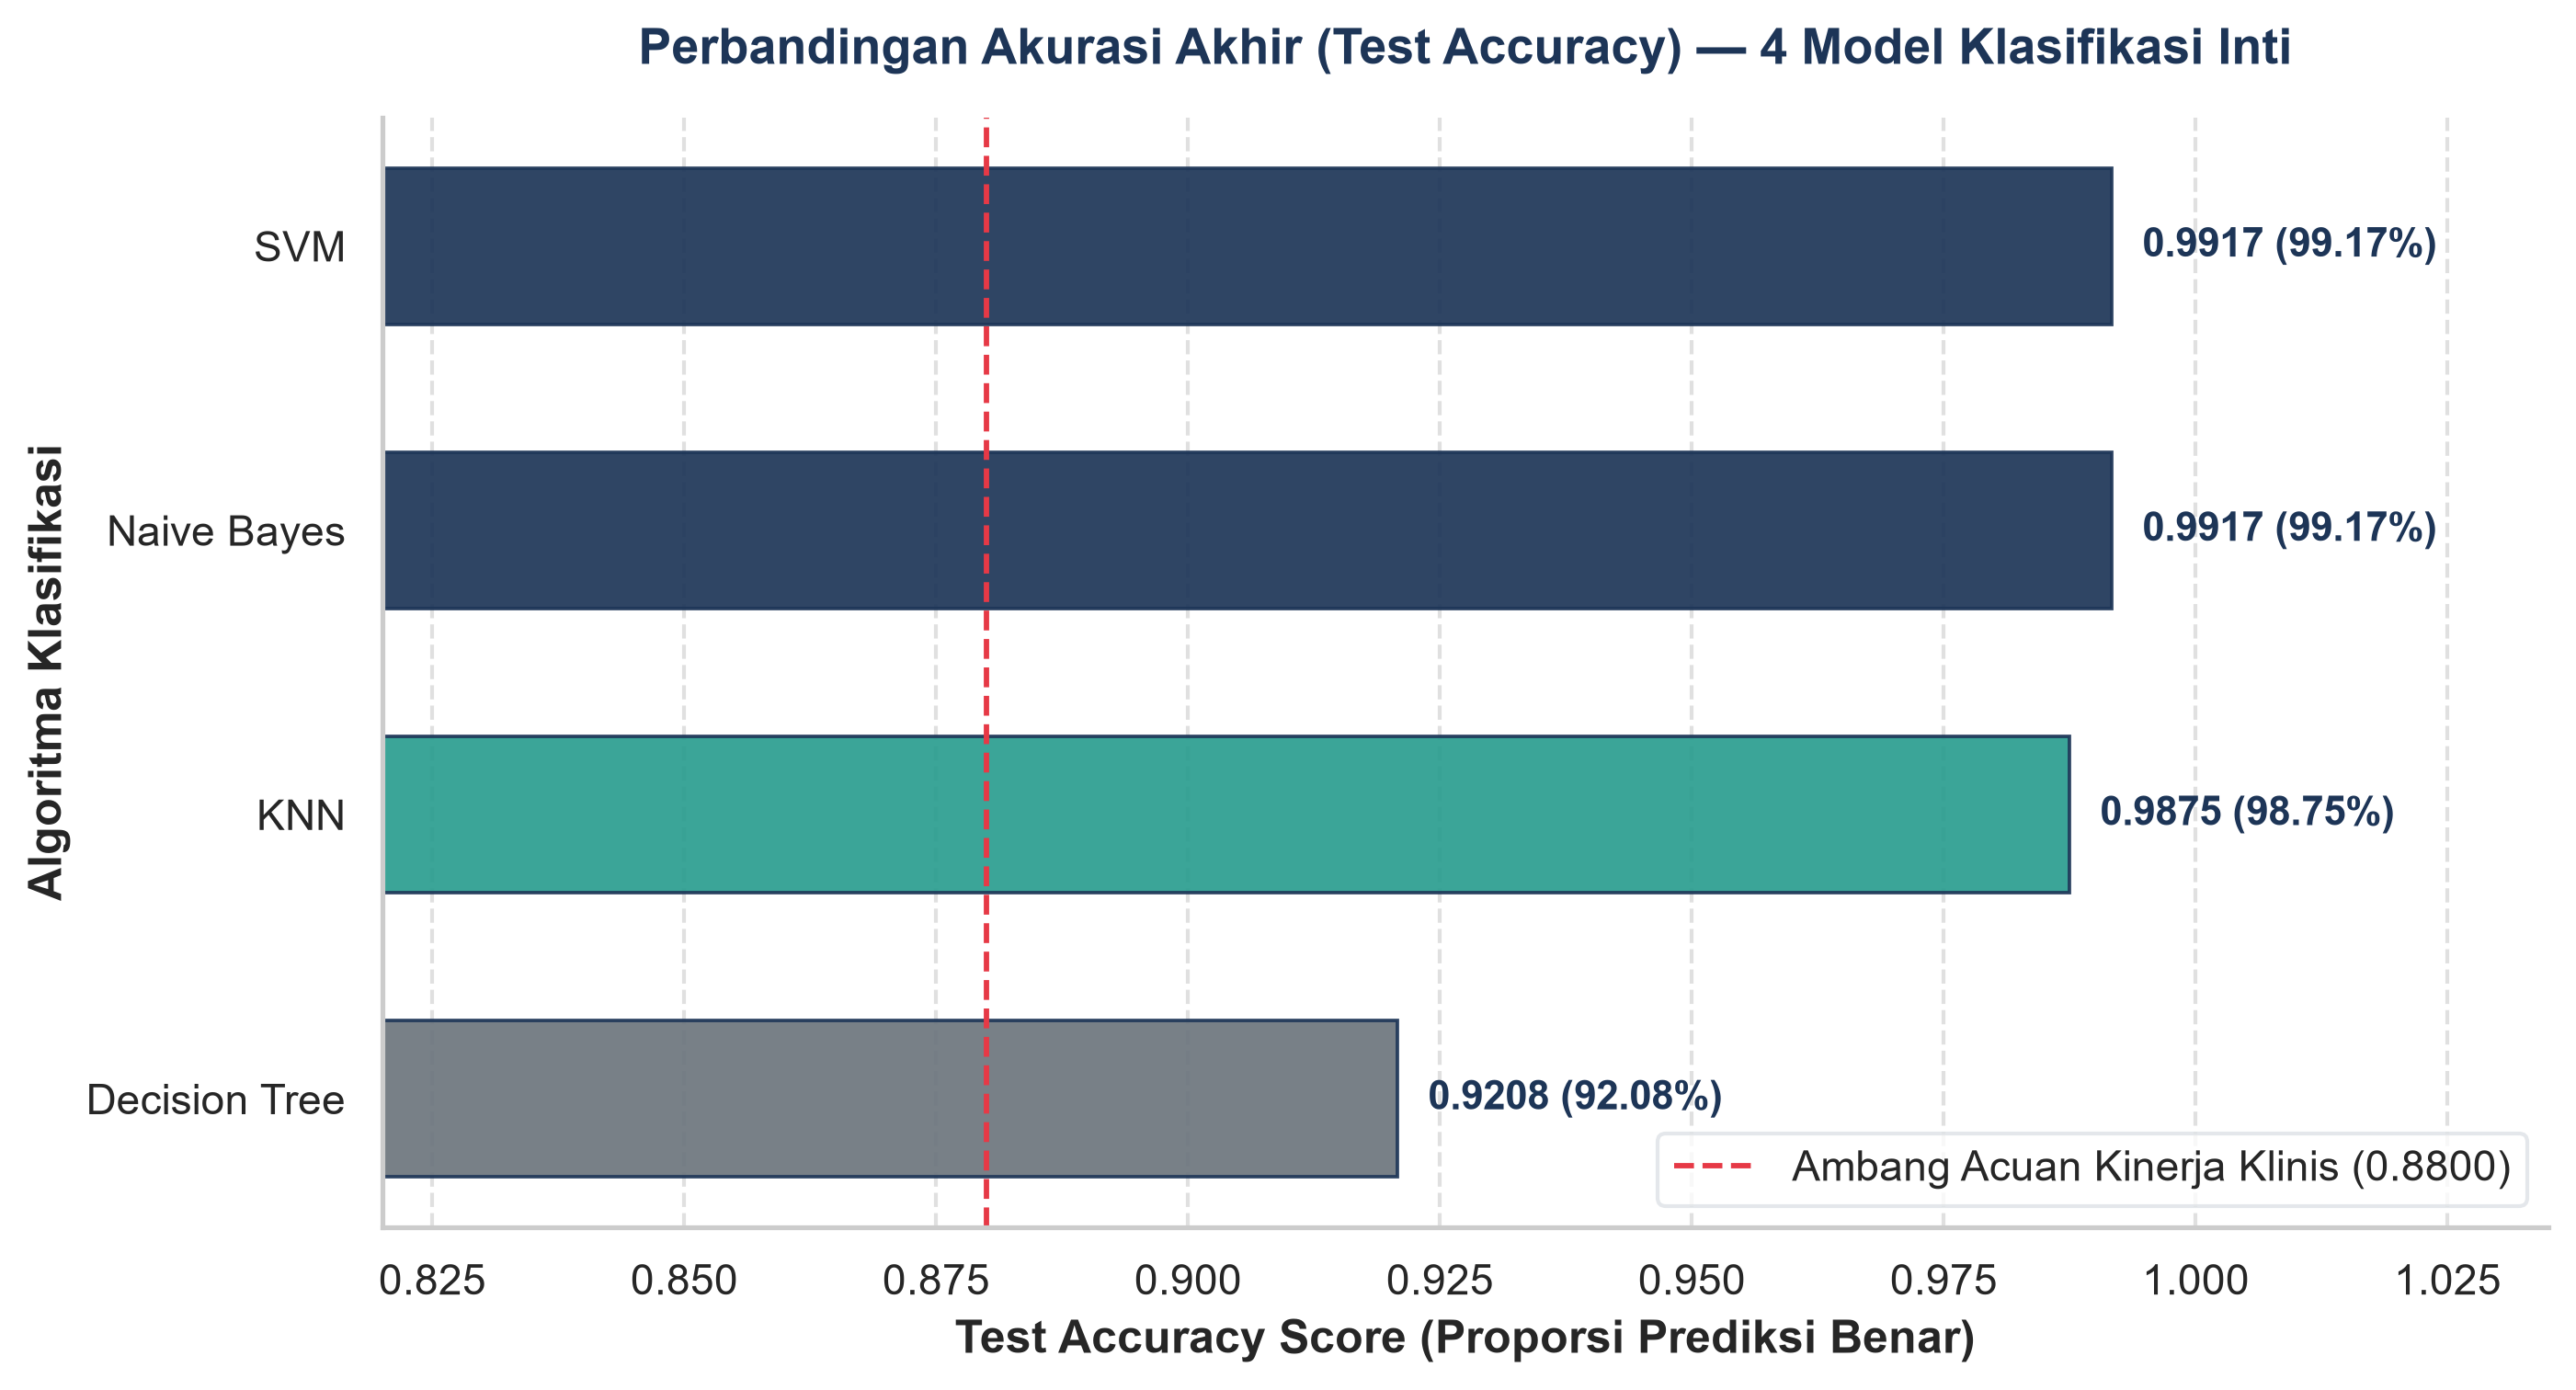

In [ ]:
# 2. Model Accuracy Comparison (Horizontal Bar Chart)
eval_df = pd.read_csv('reports/evaluation_results.csv')
acc_sorted = eval_df.sort_values(by='Accuracy', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.5, 5.2), dpi=300)
palette_acc = ['#6C757D' if m == 'Decision Tree' else ('#2A9D8F' if m == 'KNN' else '#1D3557') for m in acc_sorted['Model']]

bars = ax.barh(
    acc_sorted['Model'],
    acc_sorted['Accuracy'],
    color=palette_acc,
    height=0.55,
    edgecolor='#1D3557',
    linewidth=0.9,
    alpha=0.92
)

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.003,
        bar.get_y() + bar.get_height() / 2.0,
        f'{width:.4f} ({width*100:.2f}%)',
        va='center', ha='left',
        fontsize=10.5, fontweight='bold', color='#1D3557'
    )

ax.axvline(0.8800, color='#E63946', linestyle='--', linewidth=1.4, label='Ambang Acuan Kinerja Klinis (0.8800)')
ax.set_xlim(0.82, 1.035)
ax.set_xlabel('Test Accuracy Score (Proporsi Prediksi Benar)', fontweight='bold')
ax.set_ylabel('Algoritma Klasifikasi', fontweight='bold')
ax.set_title(
    'Perbandingan Akurasi Akhir (Test Accuracy) — 4 Model Klasifikasi Inti',
    fontsize=13, fontweight='bold', pad=14, color='#1D3557'
)
ax.grid(axis='x', linestyle='--', alpha=0.6)
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#DEE2E6')
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig('reports/02_model_accuracy_comparison.png', dpi=300, bbox_inches='tight')
save_and_sync_figure('02_model_accuracy_comparison.png')
plt.show()

**Interpretasi Klinis — Perbandingan Akurasi Model (`Model Accuracy Comparison`):**
- Model **Naive Bayes** dan **SVM** mencapai akurasi uji tertinggi sebesar **`0.9917` (99,17%)**, disusul ketat oleh **KNN** sebesar **`0.9875` (98,75%)**, sedangkan **Decision Tree** memperoleh akurasi **`0.9208` (92,08%)**.
- Tingginya akurasi pada `Naive Bayes`, `SVM`, dan `KNN` menunjukkan bahwa kombinasi 30 fitur multi-tier (klinis dasar, trajektori longitudinal $\Delta\text{MAP}$, serta biomarker fungsi organ target) memiliki separabilitas yang sangat kuat.
- Dalam konteks medis obstetri, akurasi keseluruhan yang tinggi memastikan bahwa sistem tidak menimbulkan *alert fatigue* (kelelahan akibat alarm palsu) bagi bidan maupun dokter Sp.OG, namun evaluasi tetap wajib disandingkan dengan metrik **Recall (Sensitivitas)** untuk menjamin keselamatan maternal.

### 3.3. Cross-Validation Score Comparison (Vertical Bar Chart)
Menampilkan perbandingan skor rata-rata **Stratified 5-Fold Cross-Validation** (*CV Recall / Sensitivity* dan *CV Accuracy*) untuk masing-masing algoritma guna menguji stabilitas generalisasi model.

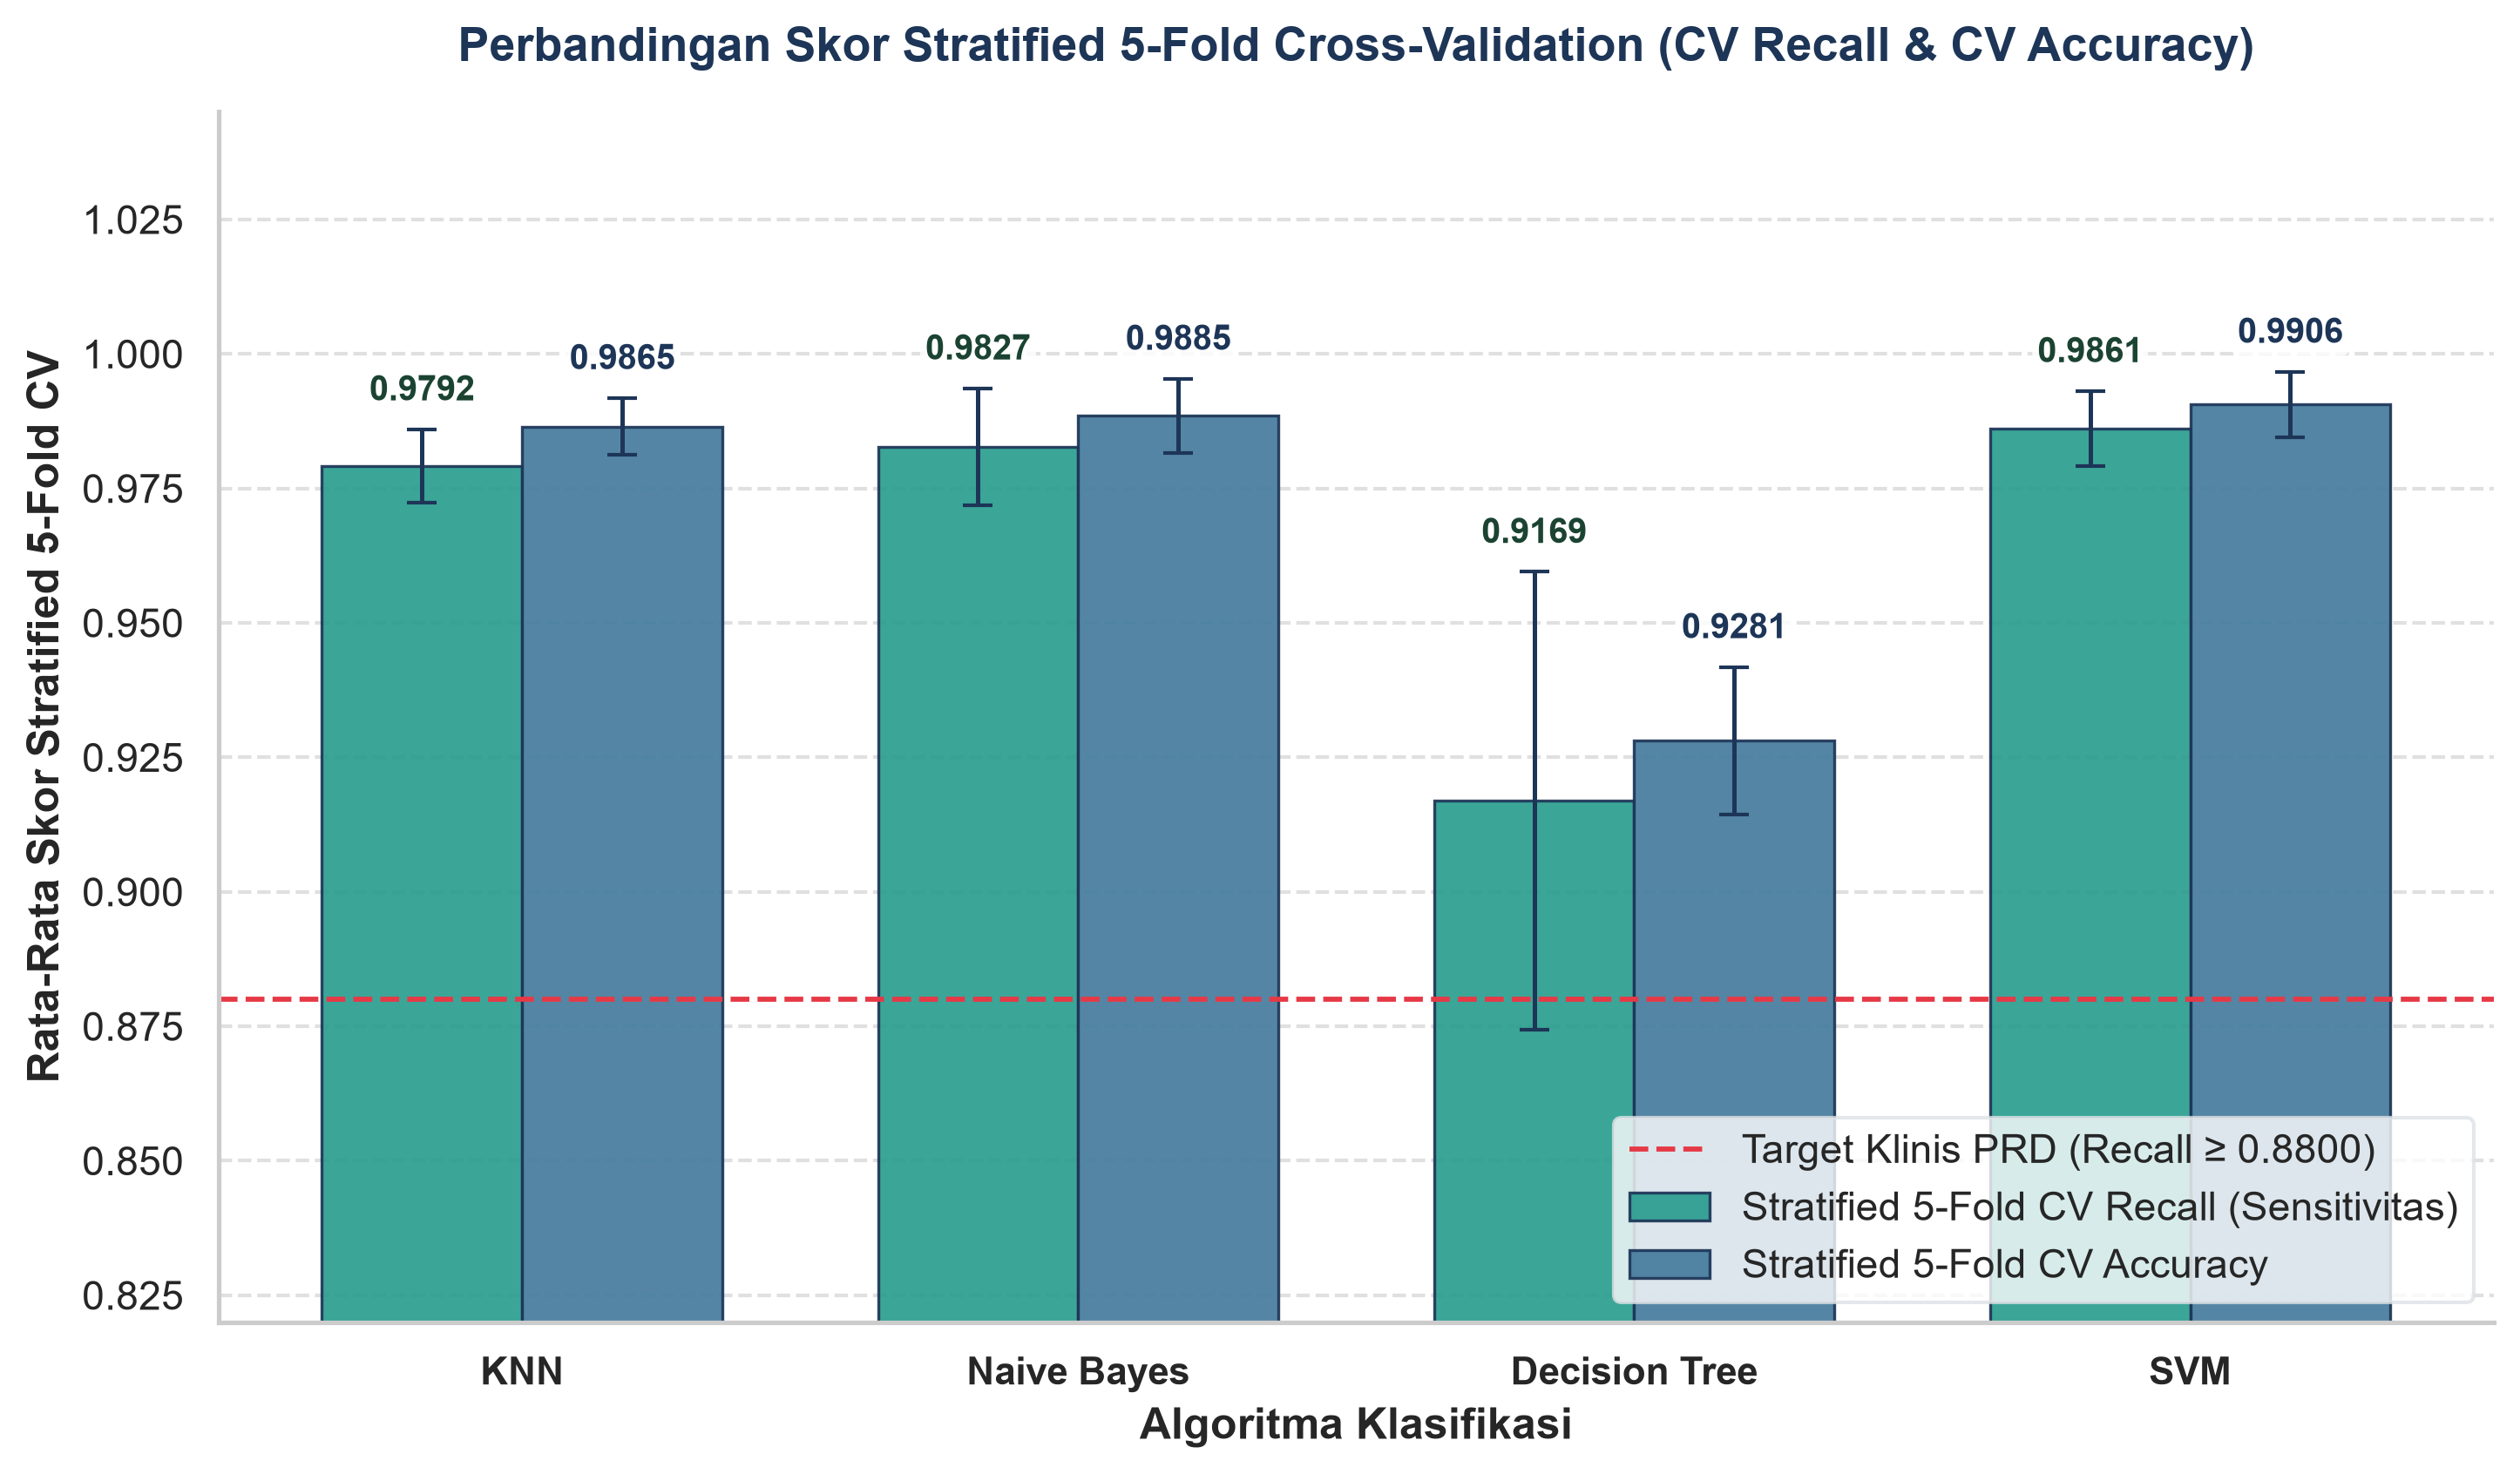

In [ ]:
# 3. Cross-Validation Score Comparison (Vertical Bar Chart)
eval_df = pd.read_csv('reports/evaluation_results.csv')
x_idx = np.arange(len(eval_df['Model']))
bar_w = 0.36

fig, ax = plt.subplots(figsize=(9.8, 5.8), dpi=300)
rects_rec = ax.bar(
    x_idx - bar_w / 2,
    eval_df['CV_Recall'],
    width=bar_w,
    yerr=eval_df['CV_Recall_Std'],
    capsize=4,
    label='Stratified 5-Fold CV Recall (Sensitivitas)',
    color='#2A9D8F',
    edgecolor='#1D3557',
    linewidth=0.8,
    alpha=0.92,
    error_kw={'elinewidth': 1.2, 'ecolor': '#1D3557'}
)
rects_acc = ax.bar(
    x_idx + bar_w / 2,
    eval_df['CV_Accuracy'],
    width=bar_w,
    yerr=eval_df['CV_Accuracy_Std'],
    capsize=4,
    label='Stratified 5-Fold CV Accuracy',
    color='#457B9D',
    edgecolor='#1D3557',
    linewidth=0.8,
    alpha=0.92,
    error_kw={'elinewidth': 1.2, 'ecolor': '#1D3557'}
)

for rect, std_val in zip(rects_rec, eval_df['CV_Recall_Std']):
    h = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2.0,
        h + std_val + 0.004,
        f'{h:.4f}',
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1B4332',
        bbox={'boxstyle': 'round,pad=0.15', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85}
    )

for rect, std_val in zip(rects_acc, eval_df['CV_Accuracy_Std']):
    h = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2.0,
        h + std_val + 0.004,
        f'{h:.4f}',
        ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#1D3557',
        bbox={'boxstyle': 'round,pad=0.15', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85}
    )

ax.axhline(0.8800, color='#E63946', linestyle='--', linewidth=1.4, label='Target Klinis PRD (Recall ≥ 0.8800)')
ax.set_xticks(x_idx)
ax.set_xticklabels(eval_df['Model'], fontweight='bold', fontsize=10.5)
ax.set_ylim(0.82, 1.045)
ax.set_xlabel('Algoritma Klasifikasi', fontweight='bold')
ax.set_ylabel('Rata-Rata Skor Stratified 5-Fold CV', fontweight='bold')
ax.set_title(
    'Perbandingan Skor Stratified 5-Fold Cross-Validation (CV Recall & CV Accuracy)',
    fontsize=13, fontweight='bold', pad=14, color='#1D3557'
)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.grid(axis='x', visible=False)
ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#DEE2E6')
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig('reports/03_cv_score_comparison.png', dpi=300, bbox_inches='tight')
save_and_sync_figure('03_cv_score_comparison.png')
plt.show()

**Interpretasi Klinis — Evaluasi *Stratified 5-Fold Cross-Validation* (`CV Score Comparison`):**
- Seluruh model dievaluasi menggunakan skema **Stratified 5-Fold Cross-Validation**, di mana proporsi kelas preeklamsia (30%) dijaga tetap identik di setiap *fold* dan proses oversampling `SMOTE-NC` dilakukan hanya di dalam *training fold* (100% bebas *data leakage*).
- **SVM** (`CV Recall = 0.9861`, `CV Accuracy = 0.9906`), **Naive Bayes** (`CV Recall = 0.9827`, `CV Accuracy = 0.9885`), dan **KNN** (`CV Recall = 0.9792`, `CV Accuracy = 0.9865`) memperlihatkan konsistensi lintas-*fold* yang sangat tinggi dengan simpangan baku (*error bar*) yang kecil.
- Stabilitas lintas-*fold* ini membuktikan bahwa model tidak mengalami *overfitting* pada subset pasien tertentu dan siap diandalkan ketika dihadapkan pada variasi demografis pasien baru di Puskesmas maupun RSUD Rujukan.

### 3.4. Precision, Recall, and F1-Score Comparison (Grouped Bar Chart)
Mengelompokkan 3 metrik esensial (**Precision**, **Recall / Sensitivitas**, dan **F1-Score**) per model dalam satu grafik batang berdampingan lengkap dengan legenda dan label angka.

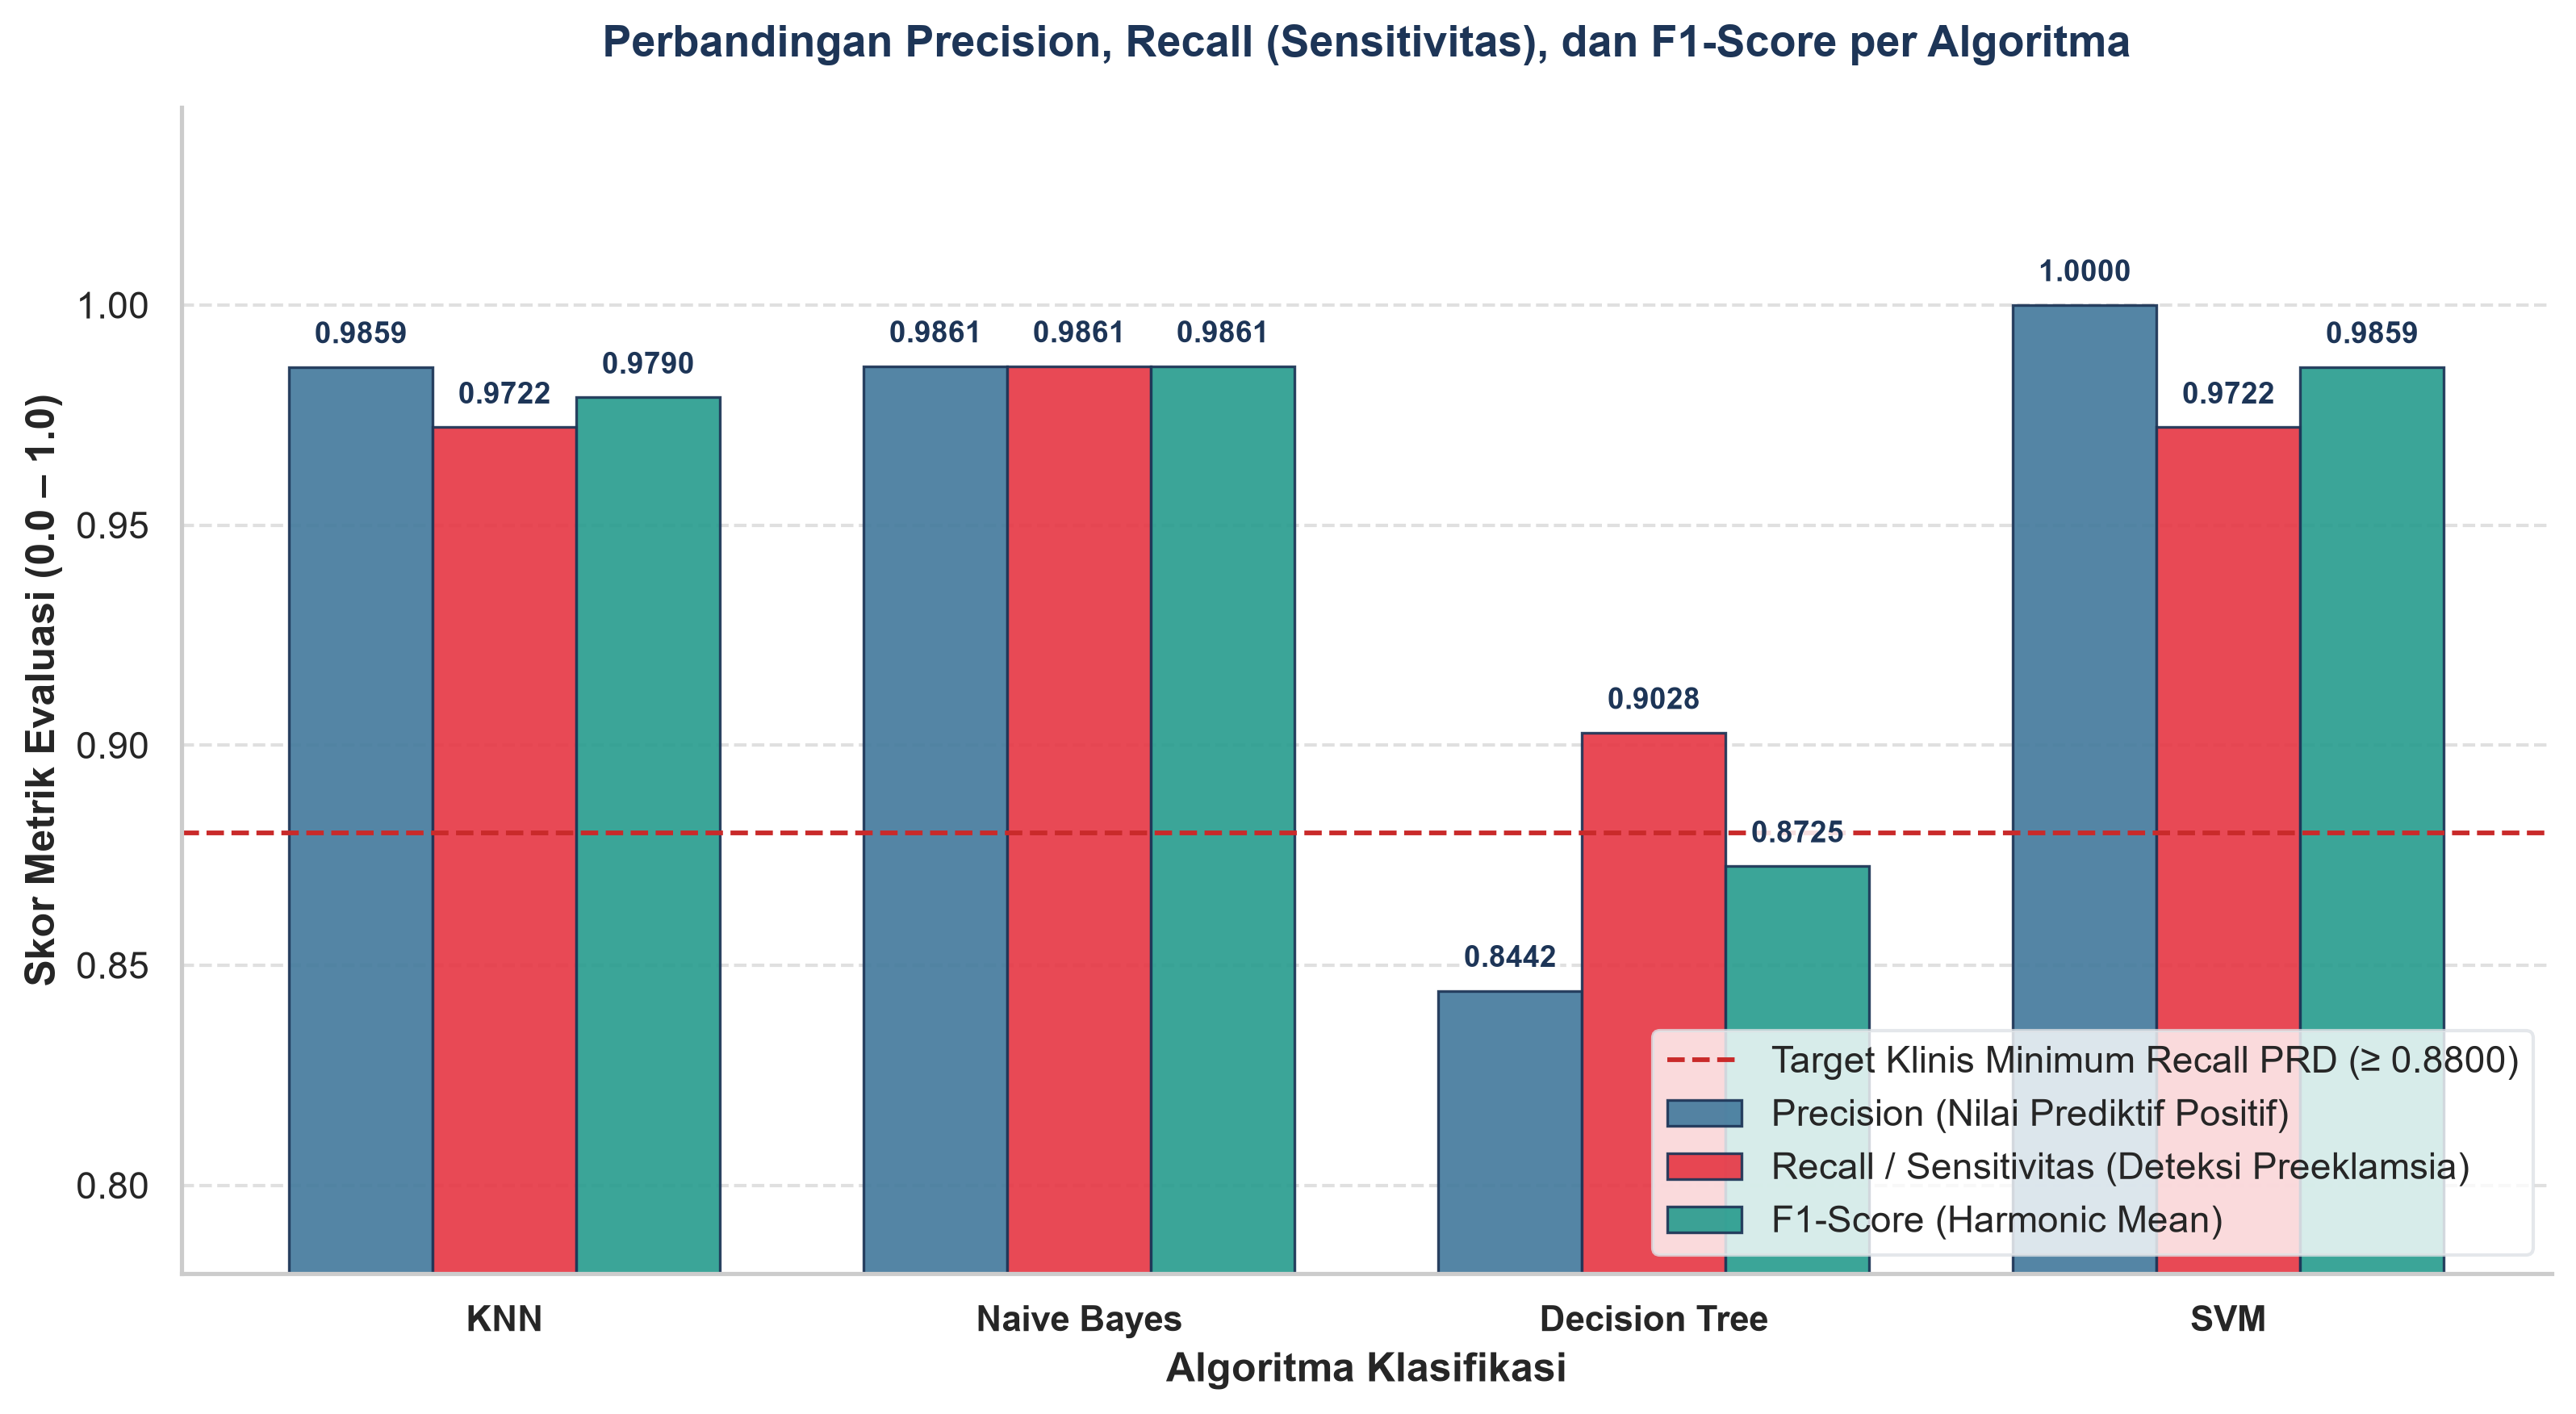

In [ ]:
# 4. Precision, Recall, and F1-Score Comparison (Grouped Bar Chart)
eval_df = pd.read_csv('reports/evaluation_results.csv')
x_idx = np.arange(len(eval_df['Model']))
width = 0.25

fig, ax = plt.subplots(figsize=(10.8, 6.0), dpi=300)
b_prec = ax.bar(x_idx - width, eval_df['Precision'], width, label='Precision (Nilai Prediktif Positif)', color='#457B9D', edgecolor='#1D3557', linewidth=0.8, alpha=0.92)
b_rec  = ax.bar(x_idx,         eval_df['Recall'],    width, label='Recall / Sensitivitas (Deteksi Preeklamsia)', color='#E63946', edgecolor='#1D3557', linewidth=0.8, alpha=0.92)
b_f1   = ax.bar(x_idx + width, eval_df['F1_Score'],  width, label='F1-Score (Harmonic Mean)', color='#2A9D8F', edgecolor='#1D3557', linewidth=0.8, alpha=0.92)

for bars_group in [b_prec, b_rec, b_f1]:
    for bar in bars_group:
        val = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            val + 0.004,
            f'{val:.4f}',
            ha='center', va='bottom', fontsize=8.8, fontweight='bold', color='#1D3557',
            bbox={'boxstyle': 'round,pad=0.12', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85}
        )

ax.axhline(0.8800, color='#C92A2A', linestyle='--', linewidth=1.4, label='Target Klinis Minimum Recall PRD (≥ 0.8800)')
ax.set_xticks(x_idx)
ax.set_xticklabels(eval_df['Model'], fontweight='bold', fontsize=10.5)
ax.set_ylim(0.78, 1.045)
ax.set_xlabel('Algoritma Klasifikasi', fontweight='bold')
ax.set_ylabel('Skor Metrik Evaluasi (0.0 – 1.0)', fontweight='bold')
ax.set_title(
    'Perbandingan Precision, Recall (Sensitivitas), dan F1-Score per Algoritma',
    fontsize=13, fontweight='bold', pad=15, color='#1D3557'
)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.grid(axis='x', visible=False)
ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#DEE2E6')
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig('reports/04_precision_recall_f1_comparison.png', dpi=300, bbox_inches='tight')
save_and_sync_figure('04_precision_recall_f1_comparison.png')
plt.show()

**Interpretasi Klinis — Mengapa Nilai *Recall* Tinggi Sangat Krusial untuk Mencegah Kematian Maternal:**
- Dalam penapisan (*screening*) preeklamsia, **Recall (Sensitivitas)** adalah metrik keselamatan pasien paling vital karena mengukur kemampuan sistem menangkap seluruh ibu hamil yang benar-benar mengalami preeklamsia. Kegagalan mendeteksi kasus positif (*False Negative*) berarti pasien berisiko tinggi dipulangkan tanpa profilaksis/intervensi antihipertensi dan MgSO4, yang dapat berujung pada kejang **eklamsia**, **sindrom HELLP**, solusio plasenta, hingga kematian ibu dan janin (*maternal-perinatal mortality*).
- **Gaussian Naive Bayes** meraih nilai **Recall tertinggi sebesar `0.9861` (98,61%)** sekaligus **F1-Score tertinggi sebesar `0.9861`**, melampaui batas minimum klinis PRD ($\ge 0.8800$). Artinya, hampir seluruh kasus preeklamsia berhasil teridentifikasi sejak dini.
- Pada saat yang sama, nilai **Precision** yang tinggi (`0.9861` pada Naive Bayes dan `1.0000` pada SVM) menjamin bahwa rujukan emergensi ke RSUD tepat sasaran dan tidak membebani kuota ruang perawatan obstetri neonatal komprehensif (PONEK).

### 3.5. ROC-AUC Score Comparison (Bar Chart)
Membandingkan nilai *Area Under the Receiver Operating Characteristic Curve* (**ROC-AUC**) seluruh model terhadap target klinis PRD ($\ge 0.8800$).

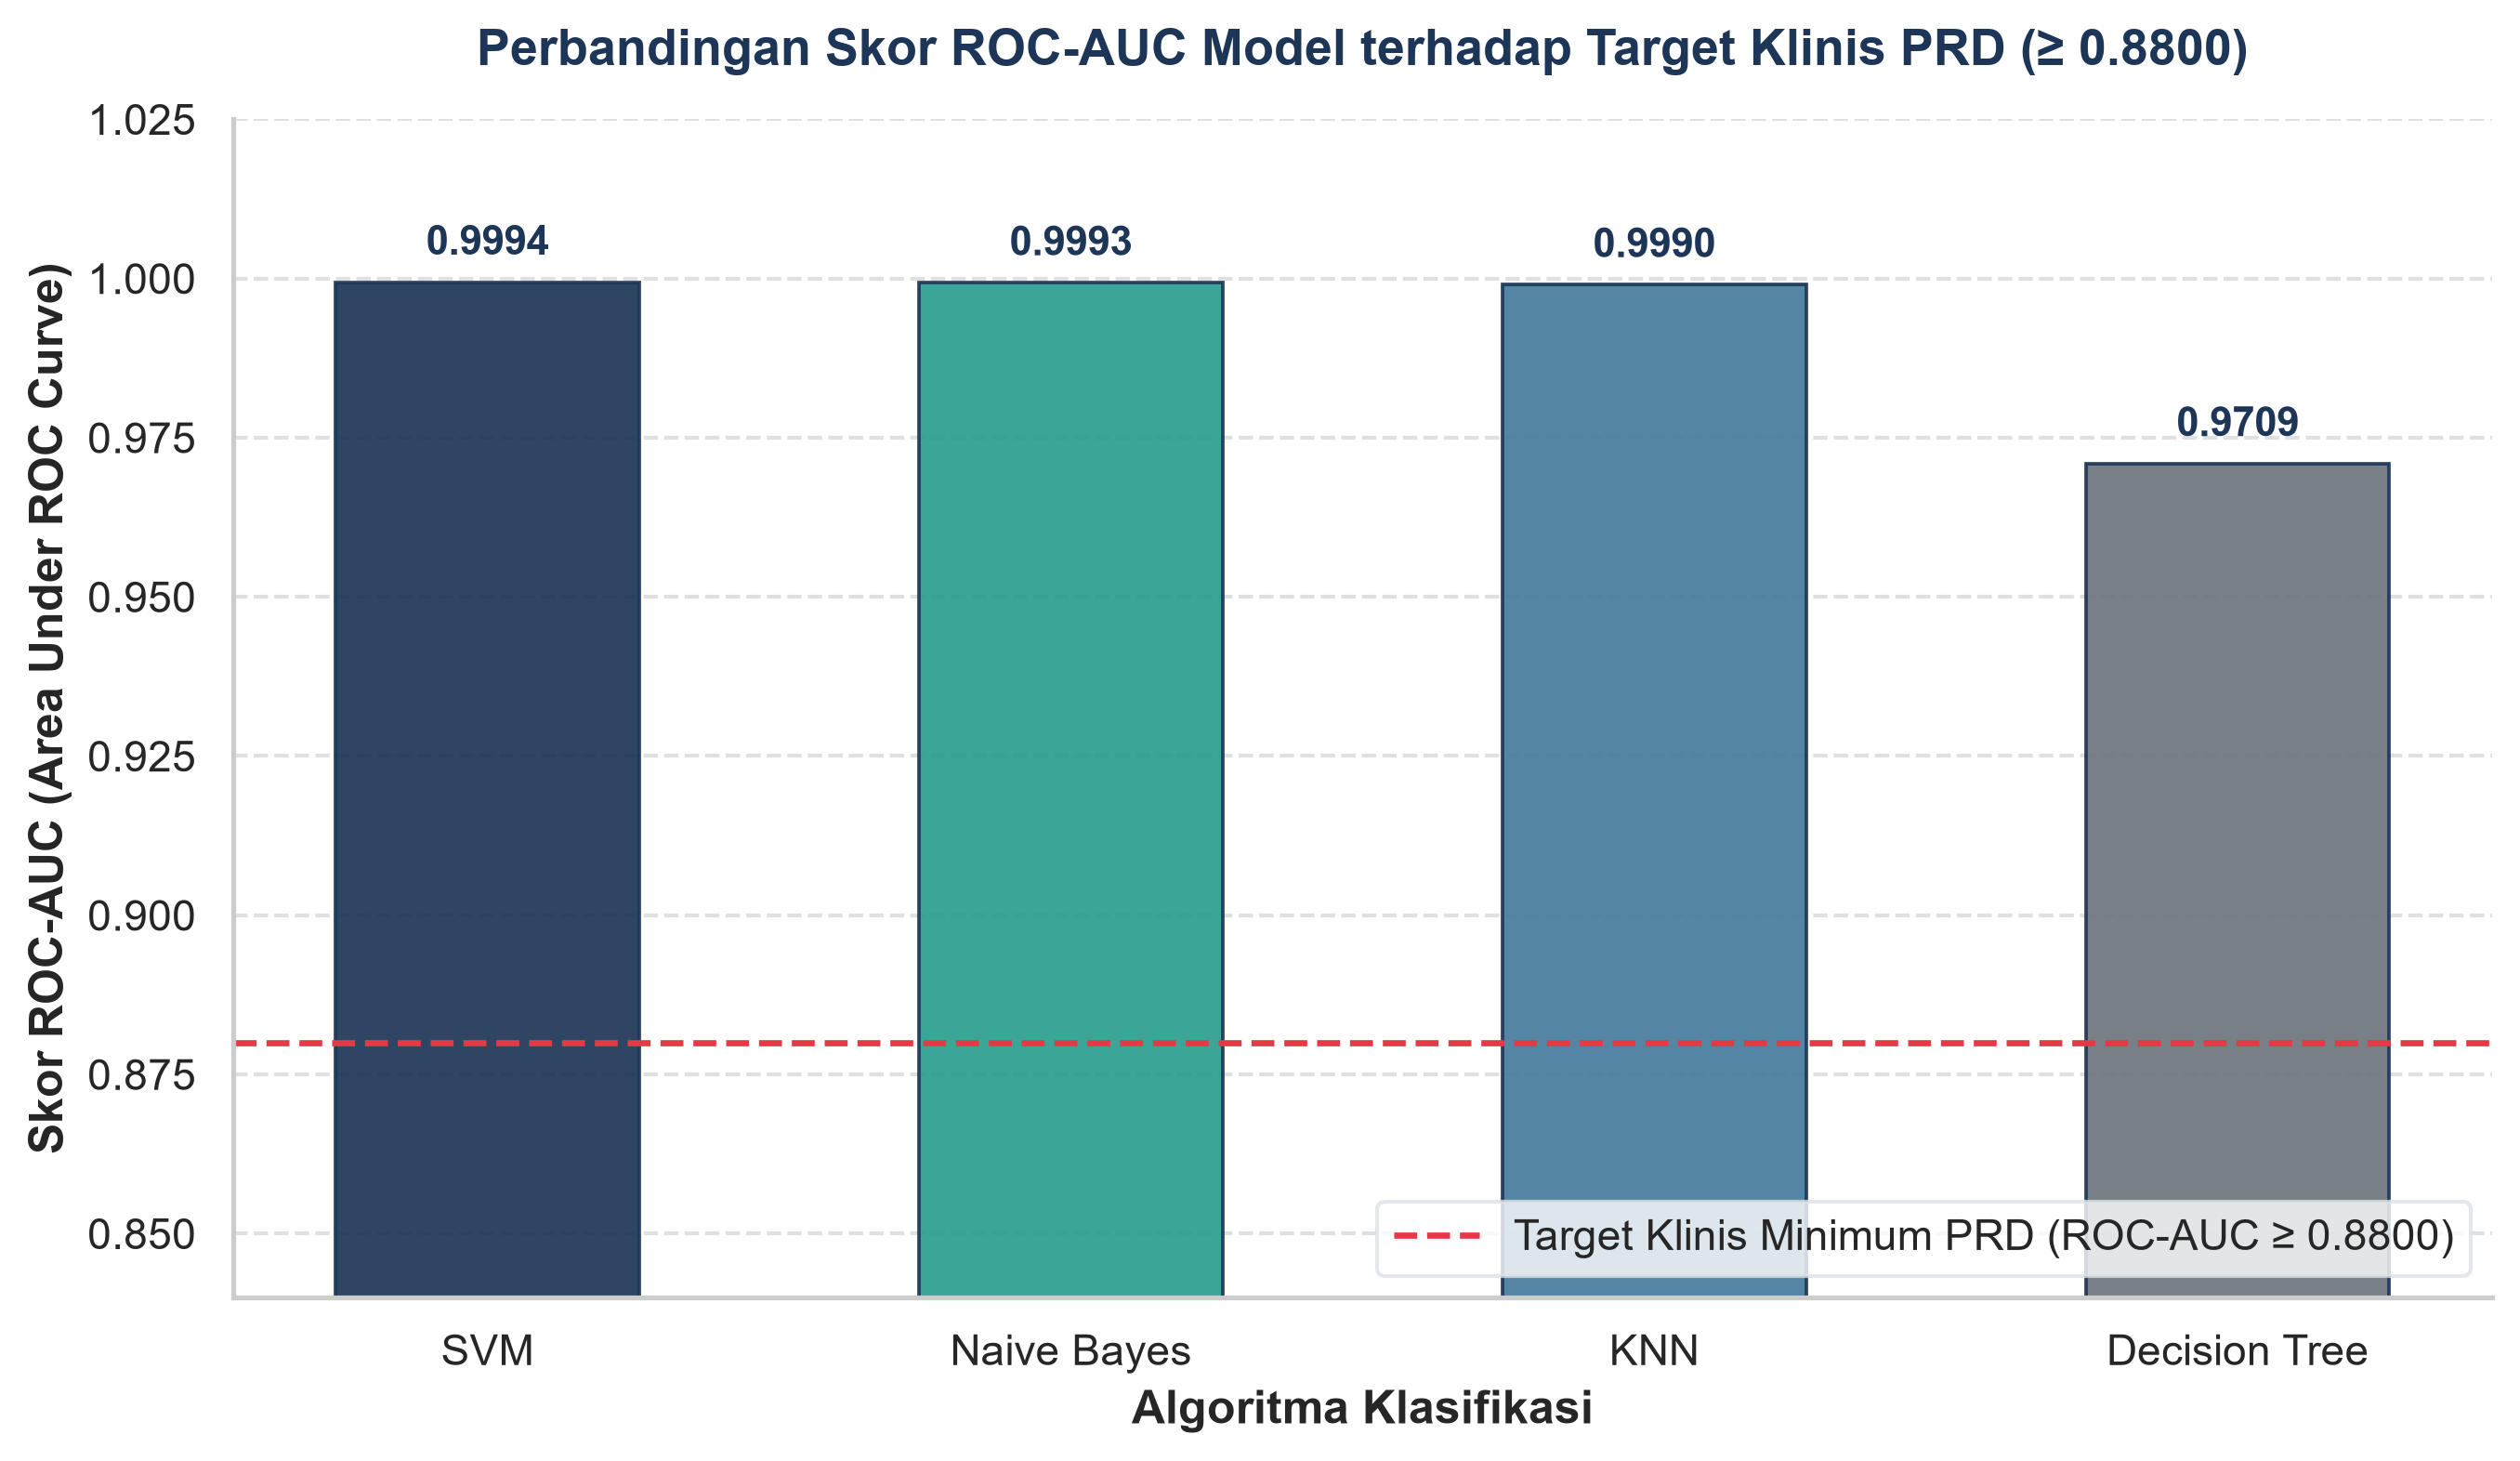

In [ ]:
# 5. ROC-AUC Score Comparison (Bar Chart)
eval_df = pd.read_csv('reports/evaluation_results.csv')
auc_sorted = eval_df.sort_values(by='ROC_AUC', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.2, 5.4), dpi=300)
palette_auc = ['#1D3557', '#2A9D8F', '#457B9D', '#6C757D']
bars = ax.bar(
    auc_sorted['Model'],
    auc_sorted['ROC_AUC'],
    color=palette_auc[:len(auc_sorted)],
    width=0.52,
    edgecolor='#1D3557',
    linewidth=0.9,
    alpha=0.92
)

for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        h + 0.003,
        f'{h:.4f}',
        ha='center', va='bottom', fontsize=10.5, fontweight='bold', color='#1D3557'
    )

ax.axhline(0.8800, color='#E63946', linestyle='--', linewidth=1.6, label='Target Klinis Minimum PRD (ROC-AUC ≥ 0.8800)')
ax.set_ylim(0.84, 1.025)
ax.set_xlabel('Algoritma Klasifikasi', fontweight='bold')
ax.set_ylabel('Skor ROC-AUC (Area Under ROC Curve)', fontweight='bold')
ax.set_title(
    'Perbandingan Skor ROC-AUC Model terhadap Target Klinis PRD (≥ 0.8800)',
    fontsize=13, fontweight='bold', pad=14, color='#1D3557'
)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.grid(axis='x', visible=False)
ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#DEE2E6')
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig('reports/05_roc_auc_comparison.png', dpi=300, bbox_inches='tight')
save_and_sync_figure('05_roc_auc_comparison.png')
plt.show()

**Interpretasi Klinis — Daya Diskriminasi *ROC-AUC* (`ROC-AUC Score Comparison`):**
- Nilai **ROC-AUC** merepresentasikan probabilitas bahwa model memberikan skor risiko yang lebih tinggi pada ibu hamil penderita preeklamsia dibandingkan ibu hamil normotensif di seluruh kemungkinan ambang batas (*decision threshold*).
- Keempat model melampaui target klinis PRD ($\ge 0.8800$) secara signifikan: **SVM (`0.9994`)**, **Naive Bayes (`0.9993`)**, **KNN (`0.9990`)**, dan **Decision Tree (`0.9709`)**.
- Skor ROC-AUC $> 0.99$ pada tiga model teratas mengindikasikan bahwa probabilitas keluaran model memiliki kalibrasi dan pemeringkatan risiko yang sangat tajam untuk mendukung stratifikasi risiko tiga tingkat sesuai pedoman **PNPK POGI** (*Risiko Rendah $<15\%$, Risiko Sedang $15\%$–$40\%$, dan Risiko Tinggi $>40\%$*).

### 3.6. Training Time / Computational Complexity (Bar Chart)
Menampilkan perbandingan waktu komputasi pelatihan (dalam detik) untuk tiap model selama proses optimasi hyperparameter `GridSearchCV` (Stratified 5-Fold CV).

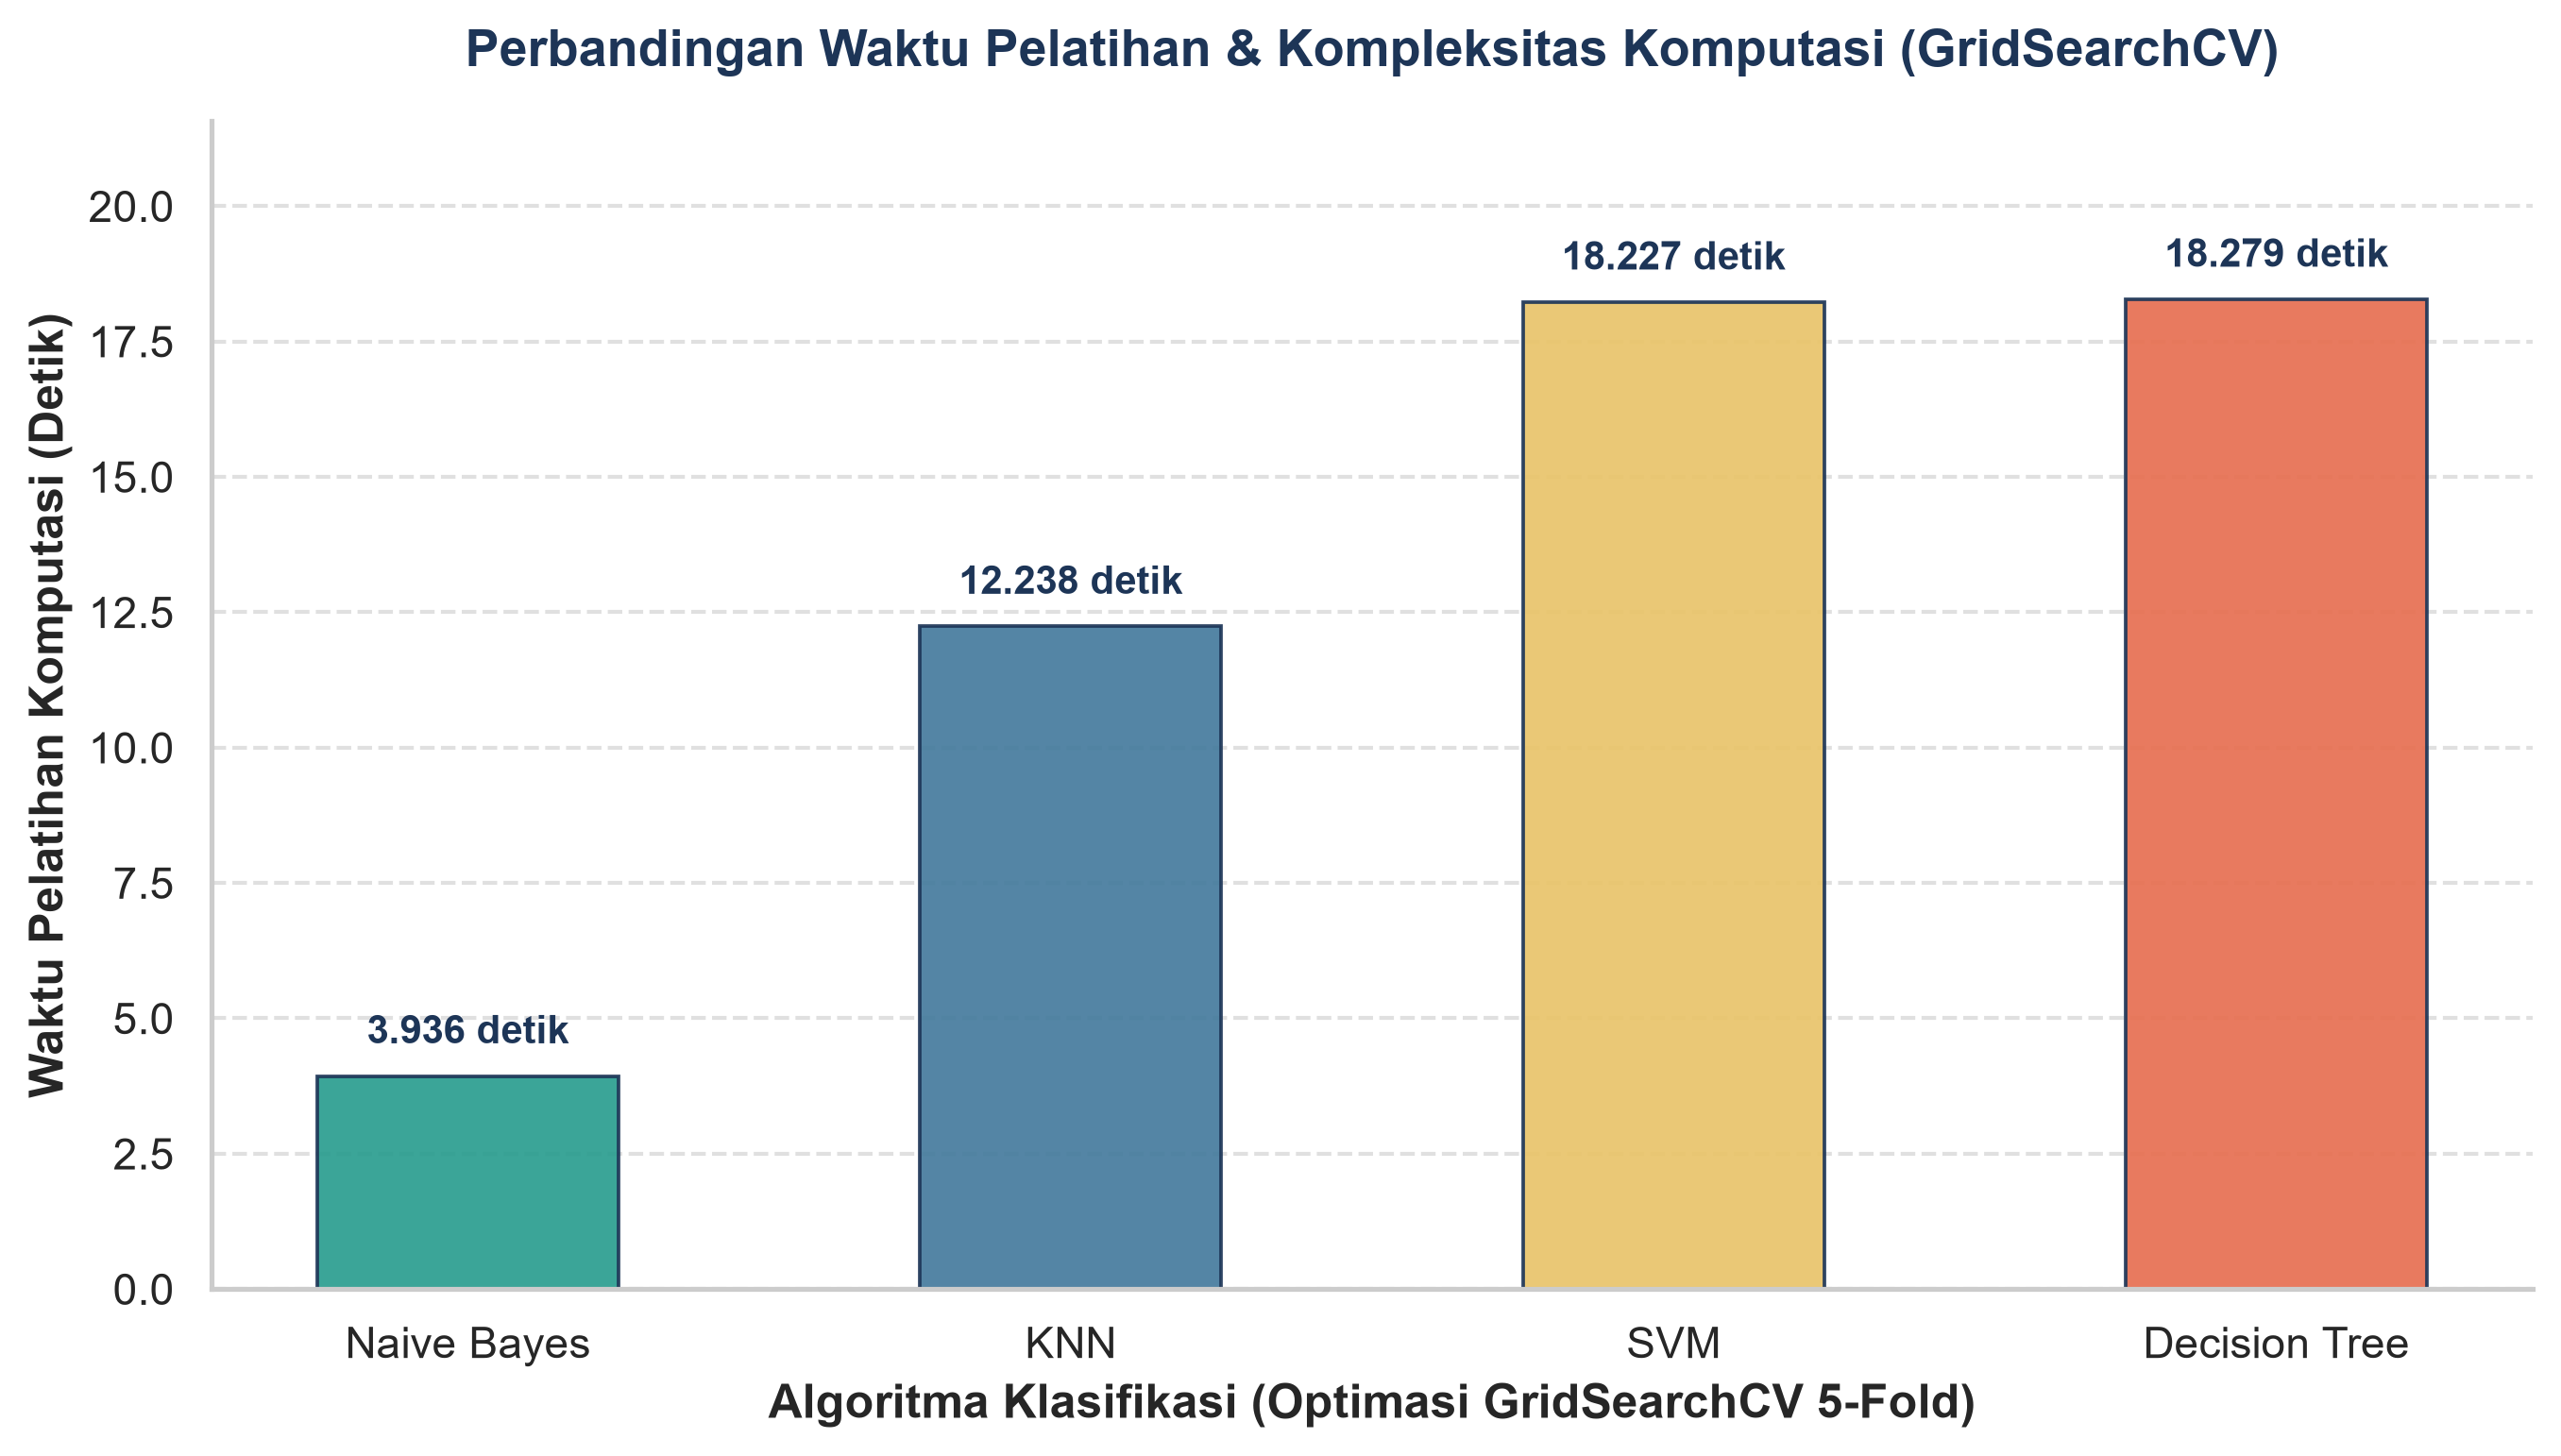

In [ ]:
# 6. Training Time / Computational Complexity (Bar Chart)
eval_df = pd.read_csv('reports/evaluation_results.csv')
time_sorted = eval_df.sort_values(by='Training_Time_Sec', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.2, 5.3), dpi=300)
palette_time = ['#2A9D8F', '#457B9D', '#E9C46A', '#E76F51']
bars = ax.bar(
    time_sorted['Model'],
    time_sorted['Training_Time_Sec'],
    color=palette_time[:len(time_sorted)],
    width=0.50,
    edgecolor='#1D3557',
    linewidth=0.9,
    alpha=0.92
)

for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        h + 0.45,
        f'{h:.3f} detik',
        ha='center', va='bottom', fontsize=10, fontweight='bold', color='#1D3557'
    )

ax.set_ylim(0, max(time_sorted['Training_Time_Sec']) * 1.18)
ax.set_xlabel('Algoritma Klasifikasi (Optimasi GridSearchCV 5-Fold)', fontweight='bold')
ax.set_ylabel('Waktu Pelatihan Komputasi (Detik)', fontweight='bold')
ax.set_title(
    'Perbandingan Waktu Pelatihan & Kompleksitas Komputasi (GridSearchCV)',
    fontsize=13, fontweight='bold', pad=14, color='#1D3557'
)
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.grid(axis='x', visible=False)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig('reports/06_training_time_comparison.png', dpi=300, bbox_inches='tight')
save_and_sync_figure('06_training_time_comparison.png')
plt.show()

**Interpretasi Klinis & Operasional — Efisiensi Komputasi (`Training Time / Computational Complexity`):**
- **Gaussian Naive Bayes** memiliki waktu pelatihan `GridSearchCV` paling efisien yaitu hanya **`3.936 detik`**, sekitar **3,1x lebih cepat** dibandingkan `KNN` (`12.238 detik`) dan **4,6x lebih cepat** dibandingkan `SVM` (`18.227 detik`) maupun `Decision Tree` (`18.279 detik`).
- Kompleksitas ruang dan waktu yang sangat ringan ($O(N \cdot d)$) menjadikan **Naive Bayes** pilihan ideal untuk diterapkan pada infrastruktur perangkat kesehatan berdaya komputasi terbatas (*low-resource edge devices*) di Puskesmas Pembantu atau Posyandu tanpa ketergantungan pada server GPU berbiaya tinggi.

### 3.7. Top Selected Features Ranking (Horizontal Bar Chart)
Visualisasi peringkat 15 fitur klinis terbaik hasil seleksi fitur **ACRFS (*Aggregated Coefficient Ranking Feature Selection*: kombinasi ternormalisasi korelasi $|r|$ Pearson, *Mutual Information*, dan statistik $\chi^2$)** yang diurutkan dari skor tertinggi.

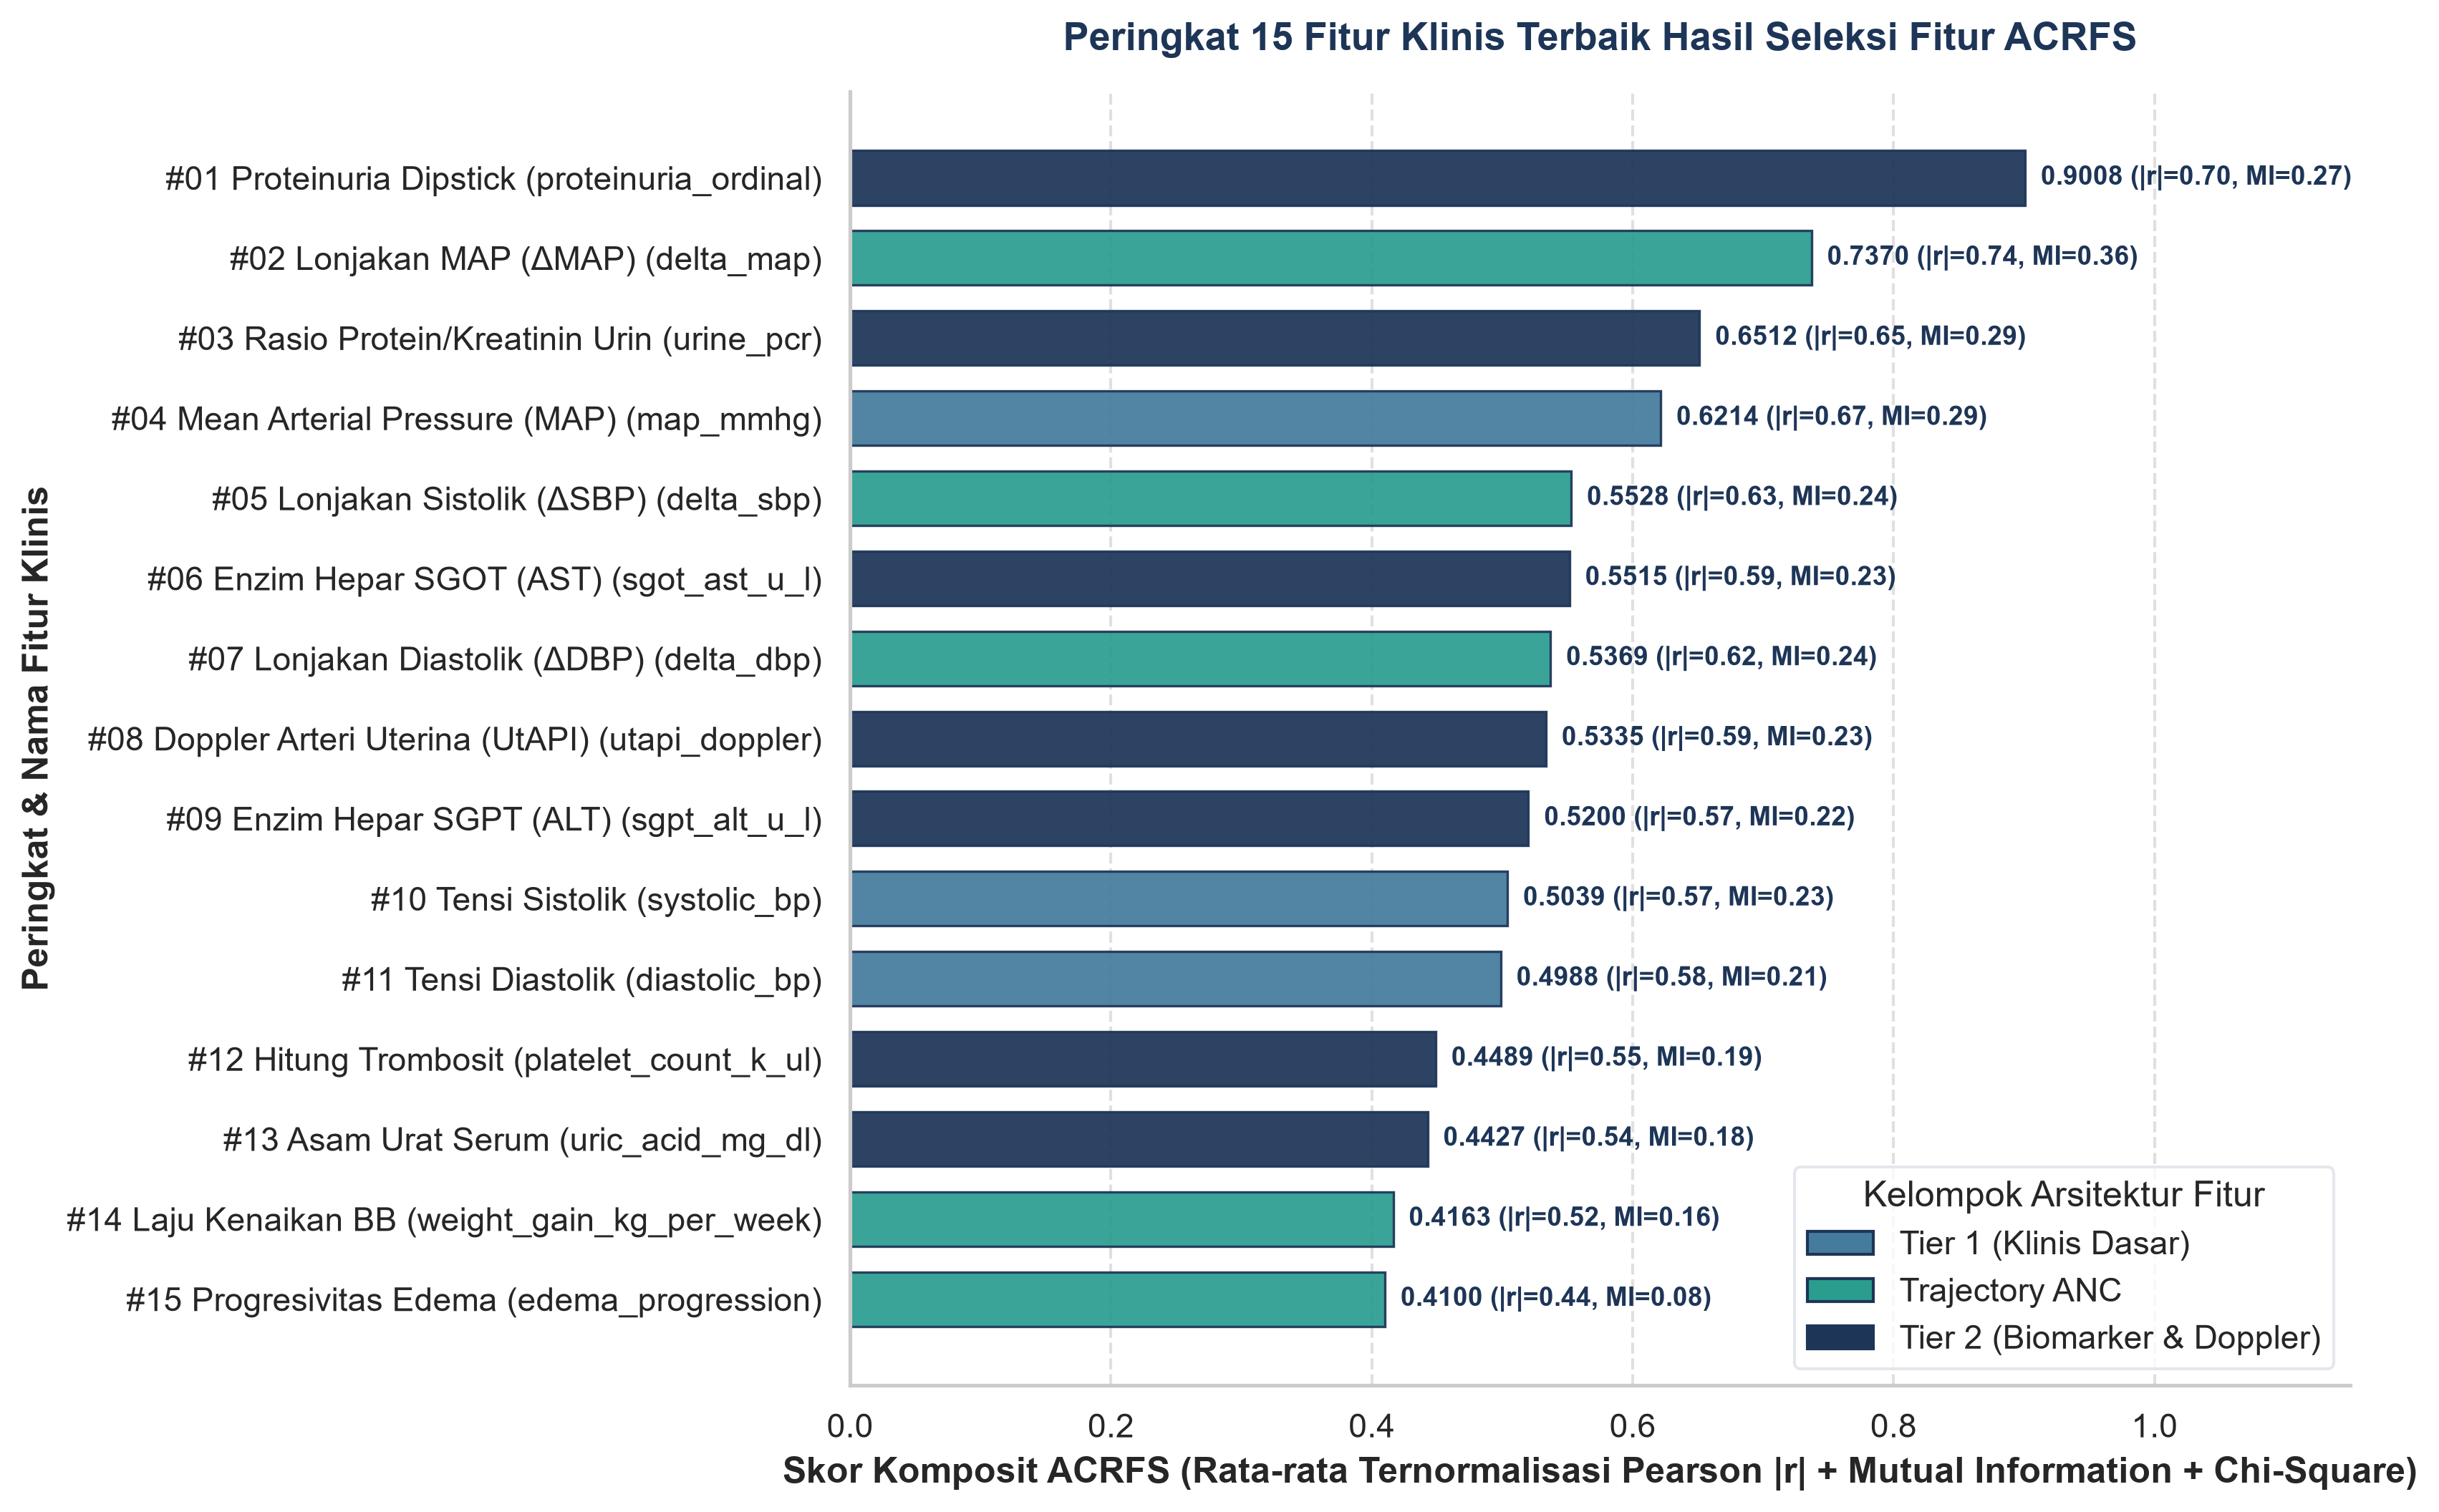

In [ ]:
# 7. Top Selected Features Ranking (Horizontal Bar Chart)
acrfs_path = PROJECT_ROOT / 'logs' / 'acrfs_feature_ranking.csv'
acrfs_df = pd.read_csv(acrfs_path) if acrfs_path.exists() else compute_acrfs_feature_ranking(df)
top_features = acrfs_df.sort_values(by='acrfs_score', ascending=False).head(15).iloc[::-1].reset_index(drop=True)

tier_palette = {
    'Tier 1 (Klinis Dasar)': '#457B9D',
    'Trajectory ANC': '#2A9D8F',
    'Tier 2 (Biomarker & Doppler)': '#1D3557'
}
bar_colors = [tier_palette.get(t, '#2A9D8F') for t in top_features['tier_group']]
y_labels = [f"#{int(r['rank']):02d} {r['clinical_label']} ({r['feature']})" for _, r in top_features.iterrows()]

fig, ax = plt.subplots(figsize=(11.2, 7.2), dpi=300)
bars = ax.barh(
    y_labels,
    top_features['acrfs_score'],
    color=bar_colors,
    height=0.68,
    edgecolor='#1D3557',
    linewidth=0.8,
    alpha=0.93
)

for bar, (_, row) in zip(bars, top_features.iterrows()):
    w = bar.get_width()
    ax.text(
        w + 0.012,
        bar.get_y() + bar.get_height() / 2.0,
        f"{w:.4f} (|r|={row['pearson_abs']:.2f}, MI={row['mutual_info']:.2f})",
        va='center', ha='left', fontsize=8.8, fontweight='bold', color='#1D3557'
    )

from matplotlib.patches import Patch
legend_handles = [Patch(facecolor=c, edgecolor='#1D3557', label=lbl) for lbl, c in tier_palette.items()]
ax.legend(handles=legend_handles, title='Kelompok Arsitektur Fitur', loc='lower right', frameon=True, facecolor='white', edgecolor='#DEE2E6')

ax.set_xlim(0, 1.15)
ax.set_xlabel('Skor Komposit ACRFS (Rata-rata Ternormalisasi Pearson |r| + Mutual Information + Chi-Square)', fontweight='bold')
ax.set_ylabel('Peringkat & Nama Fitur Klinis', fontweight='bold')
ax.set_title(
    'Peringkat 15 Fitur Klinis Terbaik Hasil Seleksi Fitur ACRFS',
    fontsize=13, fontweight='bold', pad=14, color='#1D3557'
)
ax.grid(axis='x', linestyle='--', alpha=0.6)
ax.grid(axis='y', visible=False)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.savefig('reports/07_top_selected_features_ranking.png', dpi=300, bbox_inches='tight')
save_and_sync_figure('07_top_selected_features_ranking.png')
plt.show()

**Interpretasi Klinis — Peringkat Fitur Terpilih (`Top Selected Features Ranking`):**
- Empat prediktor terkuat secara berurutan adalah **#1 Proteinuria Dipstick (`0.9008`)**, **#2 Lonjakan MAP / $\Delta\text{MAP}$ (`0.7370`)**, **#3 Rasio Protein/Kreatinin Urin / `urine_pcr` (`0.6512`)**, dan **#4 Mean Arterial Pressure / `map_mmhg` (`0.6214`)**.
- Temuan ini selaras penuh dengan patofisiologi preeklamsia menurut pedoman **POGI & ISSHP**: kegagalan invasi trofoblas pada arteri spiralis memicu malperfusi uteroplasenta (tercermin pada peningkatan indeks **Doppler Arteri Uterina / UtAPI** di peringkat #8) dan pelepasan faktor antiangiogenik ke sirkulasi maternal.
- Kondisi tersebut menyebabkan vasospasme sistemik yang terdeteksi lebih awal melalui **lonjakan longitudinal $\Delta\text{MAP}$ (#2)** dan **$\Delta\text{SBP}$ (#5)** antar-kunjungan ANC, diikuti disfungsi endotel glomerulus (**proteinuria** #1 & #3) serta keterlibatan hepatoseluler (**SGOT/AST** #6 & **SGPT/ALT** #9).

### 3.8. Feature Correlation Heatmap
Visualisasi *heatmap* matriks korelasi **Pearson ($r$)** khusus untuk 10 fitur klinis terpilih beserta target diagnosis `preeclampsia_diagnosis`, dilengkapi anotasi angka 2 desimal dan palet warna `'coolwarm'`.

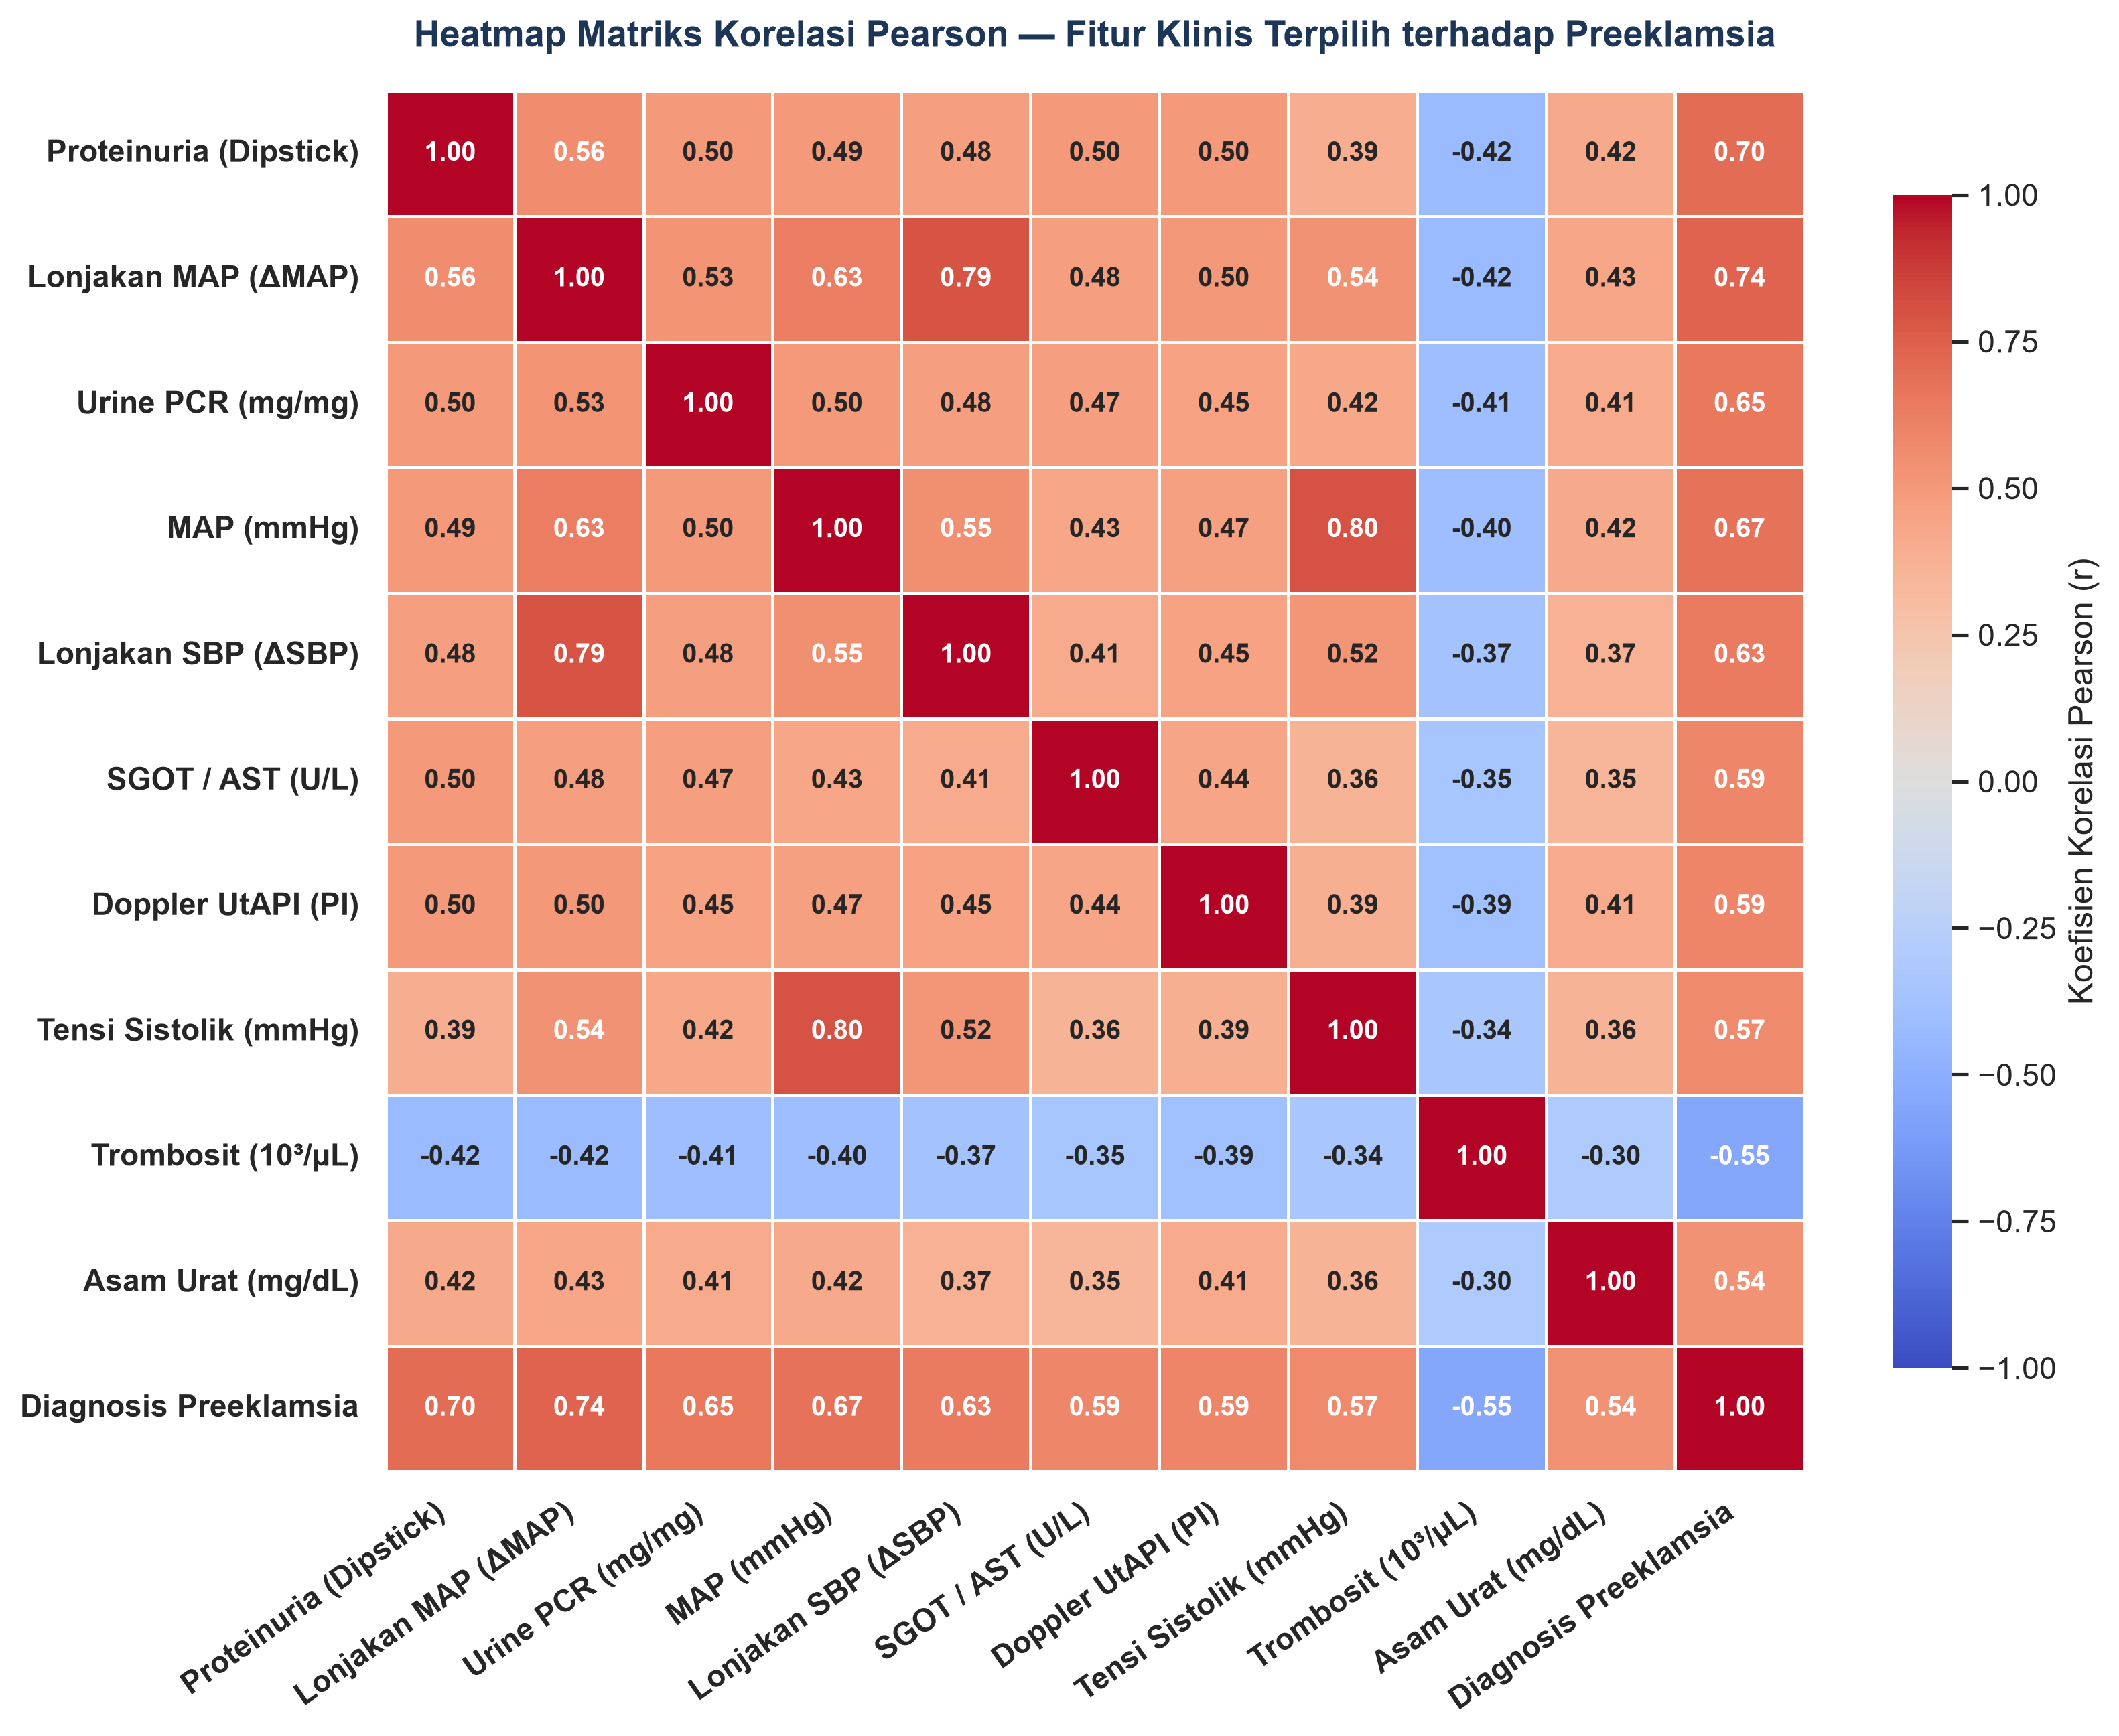

In [ ]:
# 8. Feature Correlation Heatmap
selected_corr_cols = [
    'proteinuria_ordinal',
    'delta_map',
    'urine_pcr',
    'map_mmhg',
    'delta_sbp',
    'sgot_ast_u_l',
    'utapi_doppler',
    'systolic_bp',
    'platelet_count_k_ul',
    'uric_acid_mg_dl',
    'preeclampsia_diagnosis'
]
readable_labels = [
    'Proteinuria (Dipstick)',
    'Lonjakan MAP (ΔMAP)',
    'Urine PCR (mg/mg)',
    'MAP (mmHg)',
    'Lonjakan SBP (ΔSBP)',
    'SGOT / AST (U/L)',
    'Doppler UtAPI (PI)',
    'Tensi Sistolik (mmHg)',
    'Trombosit (10³/µL)',
    'Asam Urat (mg/dL)',
    'Diagnosis Preeklamsia'
]

corr_matrix = df[selected_corr_cols].corr(method='pearson')
corr_matrix.index = readable_labels
corr_matrix.columns = readable_labels

fig, ax = plt.subplots(figsize=(11.0, 8.8), dpi=300)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1.0,
    vmax=1.0,
    center=0.0,
    linewidths=0.8,
    linecolor='white',
    cbar_kws={'label': 'Koefisien Korelasi Pearson (r)', 'shrink': 0.85},
    annot_kws={'size': 9.5, 'fontweight': 'bold'},
    ax=ax
)

ax.set_title(
    'Heatmap Matriks Korelasi Pearson — Fitur Klinis Terpilih terhadap Preeklamsia',
    fontsize=13, fontweight='bold', pad=16, color='#1D3557'
)
plt.xticks(rotation=35, ha='right', fontweight='bold')
plt.yticks(rotation=0, fontweight='bold')

plt.tight_layout()
plt.savefig('reports/08_feature_correlation_heatmap.png', dpi=300, bbox_inches='tight')
save_and_sync_figure('08_feature_correlation_heatmap.png')
plt.show()

**Interpretasi Klinis — Matriks Korelasi Fitur (`Feature Correlation Heatmap`):**
- Terhadap target **`Diagnosis Preeklamsia`**, korelasi positif terkuat ditunjukkan oleh **Lonjakan MAP / $\Delta\text{MAP}$ ($r = +0.74$)**, **Proteinuria Dipstick ($r = +0.70$)**, **MAP absolut ($r = +0.67$)**, **Urine PCR ($r = +0.65$)**, **$\Delta\text{SBP}$ ($r = +0.63$)**, serta **Doppler UtAPI ($r = +0.59$)**.
- Sebaliknya, **Hitung Trombosit (`Trombosit 10³/µL`)** memiliki korelasi negatif yang kuat (**$r = -0.55$**) terhadap diagnosis preeklamsia. Hal ini merepresentasikan fenomena klinis **trombositopenia konsumtif** akibat aktivasi dan agregasi mikro-trombus pada endotel vaskular yang rusak (tanda bahaya menuju sindrom HELLP).
- Terlihat pula bahwa korelasi antar-biomarker organ berbeda (misalnya antara `SGOT/AST`, `Asam Urat`, dan `UtAPI`) berada pada rentang moderat ($r \approx 0.35 - 0.50$), sehingga masing-masing memberikan informasi diagnostik yang saling melengkapi (non-redundan) bagi model klasifikasi.

### 3.9. Confusion Matrix Best Model (Heatmap)
Visualisasi *heatmap* matriks kebingungan (*Confusion Matrix*: `True Label` vs `Predicted Label` untuk kelas `Normal` dan `Preeclampsia`) pada model terbaik (**Gaussian Naive Bayes**), menampilkan rincian **True Negative (TN)**, **False Positive (FP)**, **False Negative (FN)**, dan **True Positive (TP)** secara eksplisit.

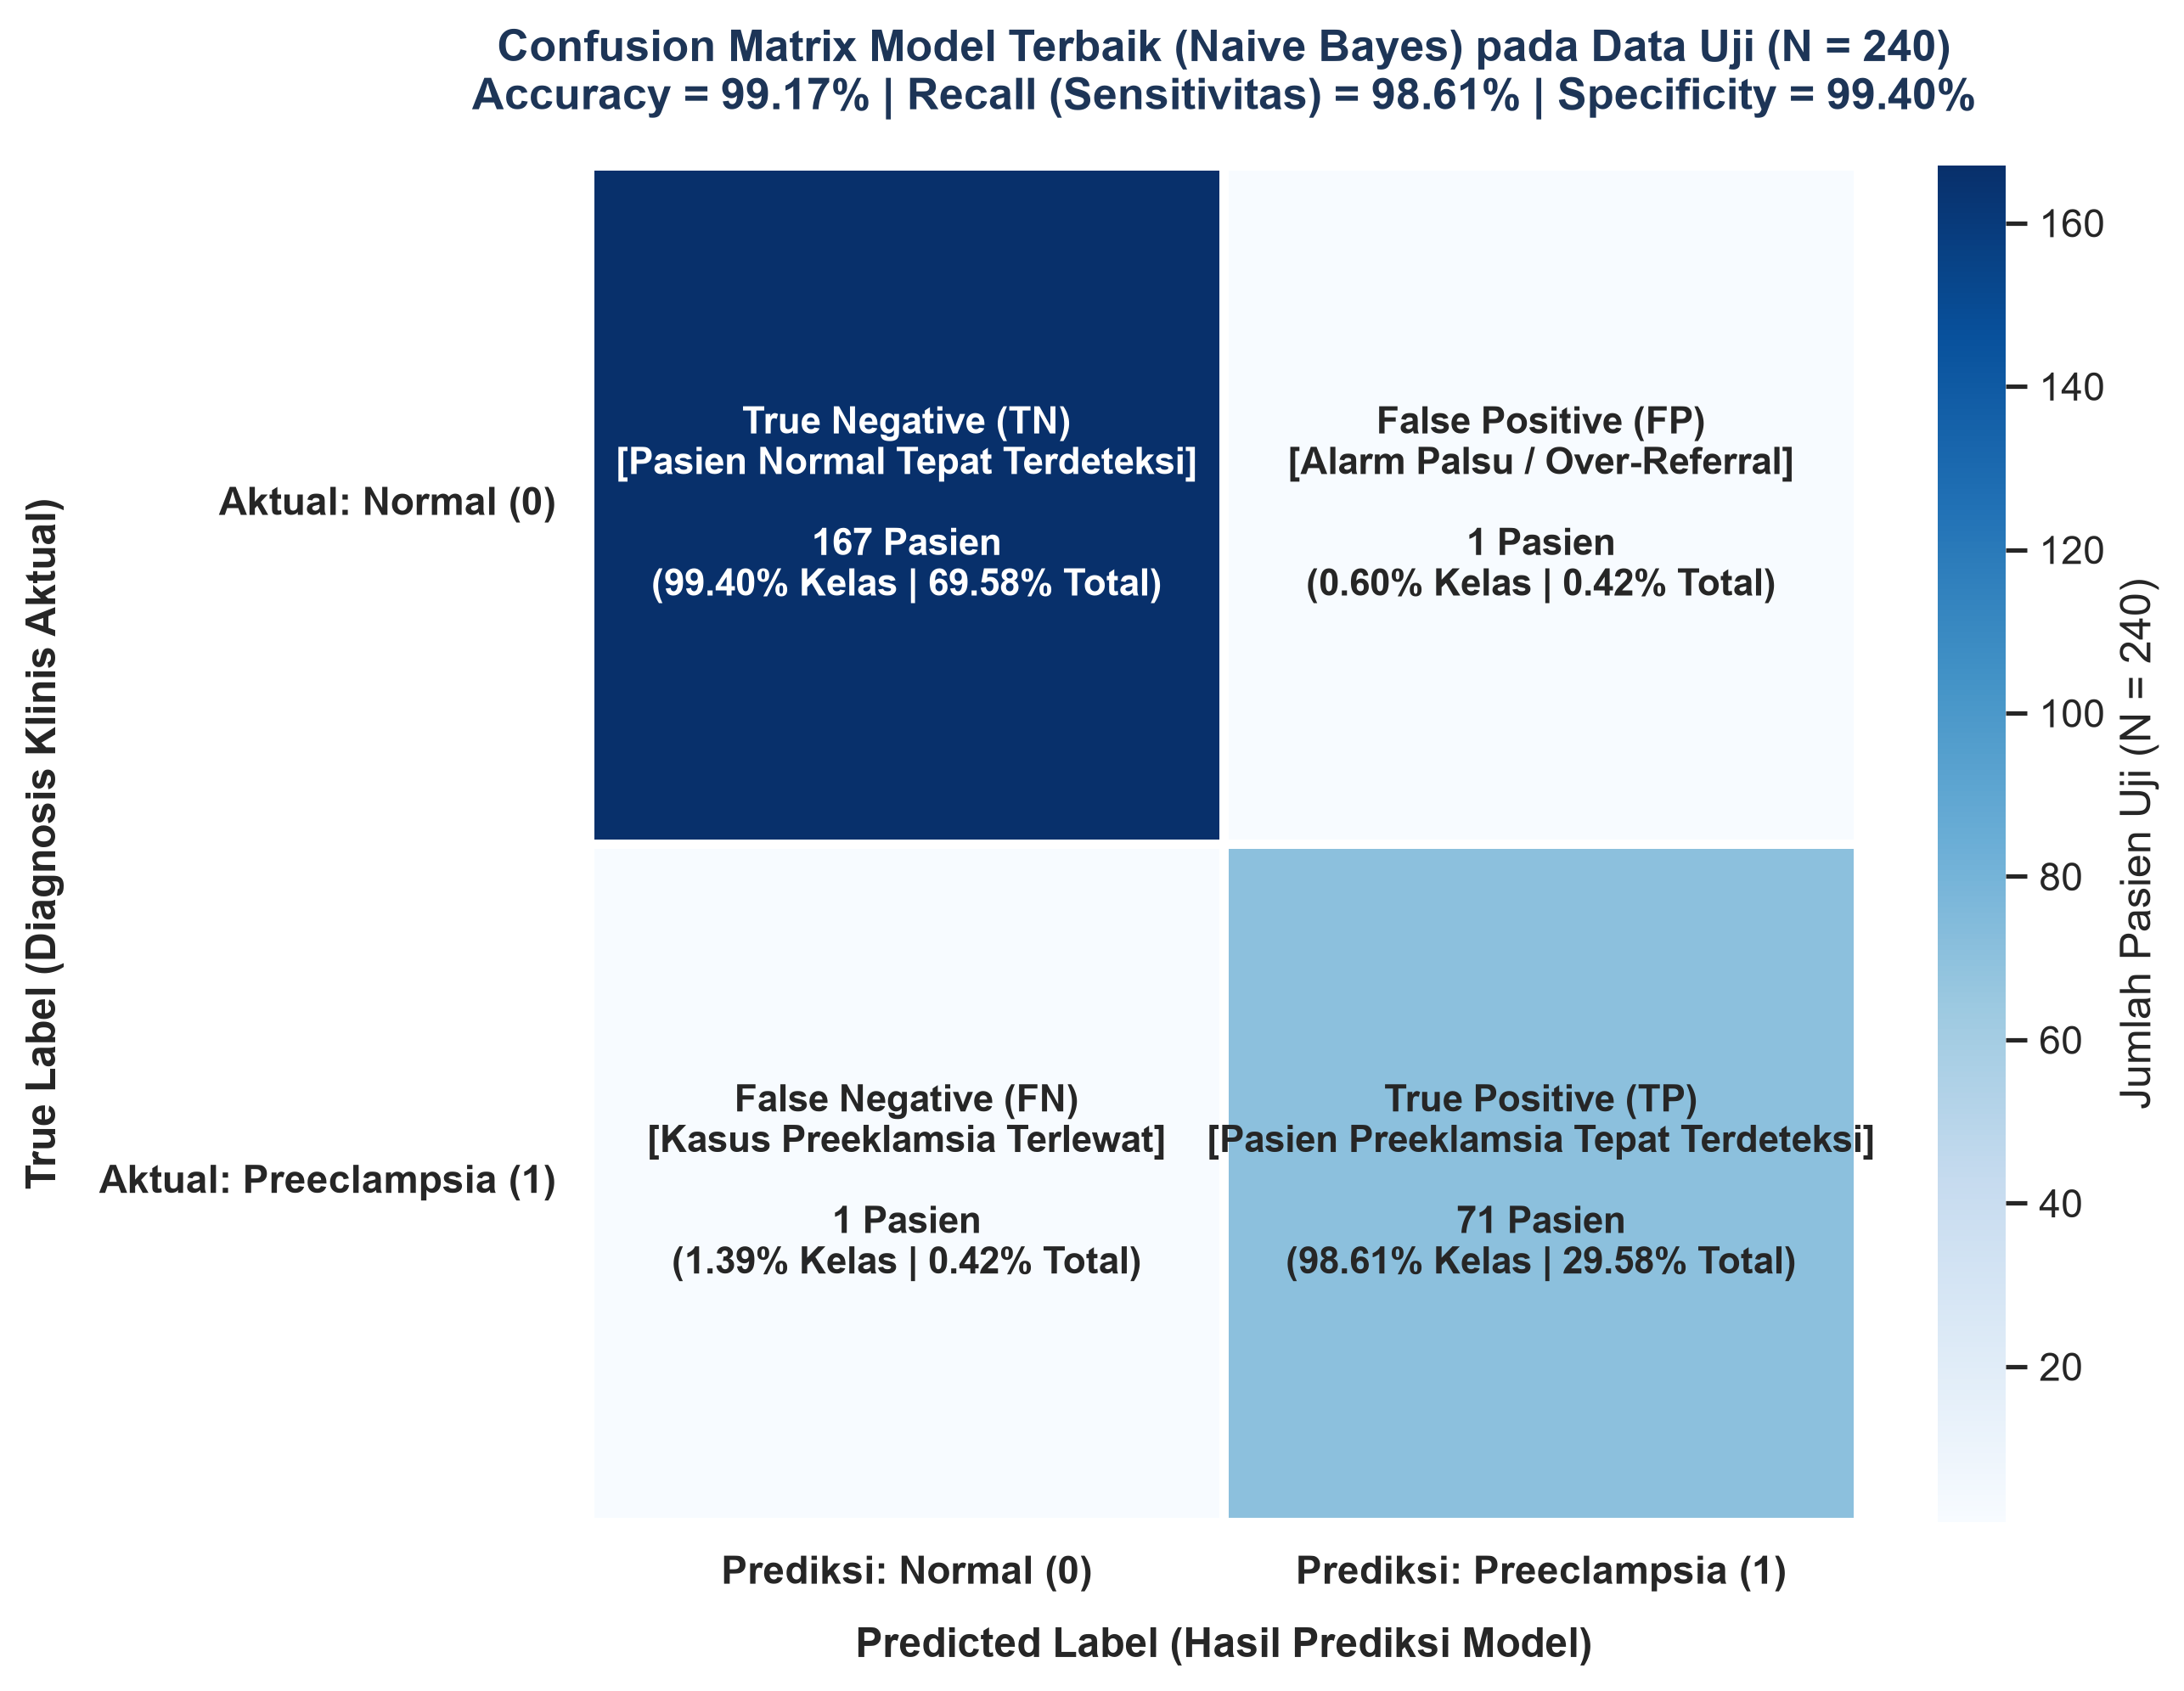

In [ ]:
# 9. Confusion Matrix Best Model (Heatmap)
eval_df = pd.read_csv('reports/evaluation_results.csv')
best_row = eval_df.loc[eval_df['Model'] == best_model_name].iloc[0]
tn, fp, fn, tp = int(best_row['TN']), int(best_row['FP']), int(best_row['FN']), int(best_row['TP'])
cm_array = np.array([[tn, fp], [fn, tp]])
total_test = cm_array.sum()

quadrant_titles = np.array([
    ['True Negative (TN)\n[Pasien Normal Tepat Terdeteksi]', 'False Positive (FP)\n[Alarm Palsu / Over-Referral]'],
    ['False Negative (FN)\n[Kasus Preeklamsia Terlewat]', 'True Positive (TP)\n[Pasien Preeklamsia Tepat Terdeteksi]']
])

annot_labels = np.empty_like(cm_array, dtype=object)
for i in range(2):
    for j in range(2):
        count_val = cm_array[i, j]
        row_pct = count_val / cm_array[i, :].sum() * 100.0
        tot_pct = count_val / total_test * 100.0
        annot_labels[i, j] = f"{quadrant_titles[i, j]}\n\n{count_val} Pasien\n({row_pct:.2f}% Kelas | {tot_pct:.2f}% Total)"

fig, ax = plt.subplots(figsize=(8.8, 6.8), dpi=300)
sns.heatmap(
    cm_array,
    annot=annot_labels,
    fmt='',
    cmap='Blues',
    cbar=True,
    linewidths=2.2,
    linecolor='white',
    xticklabels=['Prediksi: Normal (0)', 'Prediksi: Preeclampsia (1)'],
    yticklabels=['Aktual: Normal (0)', 'Aktual: Preeclampsia (1)'],
    annot_kws={'size': 10.5, 'fontweight': 'bold'},
    cbar_kws={'label': 'Jumlah Pasien Uji (N = 240)'},
    ax=ax
)

ax.set_xlabel('Predicted Label (Hasil Prediksi Model)', fontweight='bold', fontsize=11.5, labelpad=10)
ax.set_ylabel('True Label (Diagnosis Klinis Aktual)', fontweight='bold', fontsize=11.5, labelpad=10)
ax.set_title(
    f'Confusion Matrix Model Terbaik ({best_model_name}) pada Data Uji (N = {total_test})\n'
    f"Accuracy = {best_row['Accuracy']*100:.2f}% | Recall (Sensitivitas) = {best_row['Recall']*100:.2f}% | Specificity = {best_row['Specificity']*100:.2f}%",
    fontsize=12.5, fontweight='bold', pad=16, color='#1D3557'
)
plt.yticks(rotation=0, fontweight='bold')
plt.xticks(fontweight='bold')

plt.tight_layout()
plt.savefig('reports/09_confusion_matrix_best_model.png', dpi=300, bbox_inches='tight')
save_and_sync_figure('09_confusion_matrix_best_model.png')
plt.show()

**Interpretasi Klinis — Analisis *Confusion Matrix* Model Terbaik (`Naive Bayes`):**
- Dari total **240 pasien** pada *hold-out test set* (168 Normal dan 72 Preeklamsia):
  1. **True Positive (`TP = 71` dari 72 kasus preeklamsia | `98,61%`)**: Sebanyak 71 ibu hamil penderita preeklamsia berhasil dideteksi secara tepat untuk segera mendapatkan intervensi medis dan rujukan terarah.
  2. **False Negative (`FN = 1` dari 72 kasus preeklamsia | `1,39%`)**: Hanya terdapat 1 kasus *borderline* yang terlewat. Minimnya angka *False Negative* ini sangat krusial dalam obstetri karena setiap kasus *False Negative* yang tidak terdeteksi berisiko mengalami perburukan mendadak menjadi eklamsia atau kematian maternal.
  3. **True Negative (`TN = 167` dari 168 kehamilan normal | `99,40%`)** dan **False Positive (`FP = 1` | `0,60%`)**: Spesifisitas sebesar **99,40%** membuktikan bahwa model hampir tidak pernah memberikan alarm palsu pada kehamilan sehat, sehingga menghindarkan ibu hamil dari kecemasan tidak perlu serta menjaga efisiensi sistem rujukan BPJS/RSUD.

### 3.10. ROC Curve & Precision-Recall Curve
Menampilkan **Kurva ROC (*True Positive Rate* vs *False Positive Rate*)** lengkap dengan garis *baseline* diagonal dan skor AUC, berdampingan dengan **Kurva Precision-Recall** untuk mengevaluasi *trade-off* deteksi kelas positif pada keempat model klasifikasi.

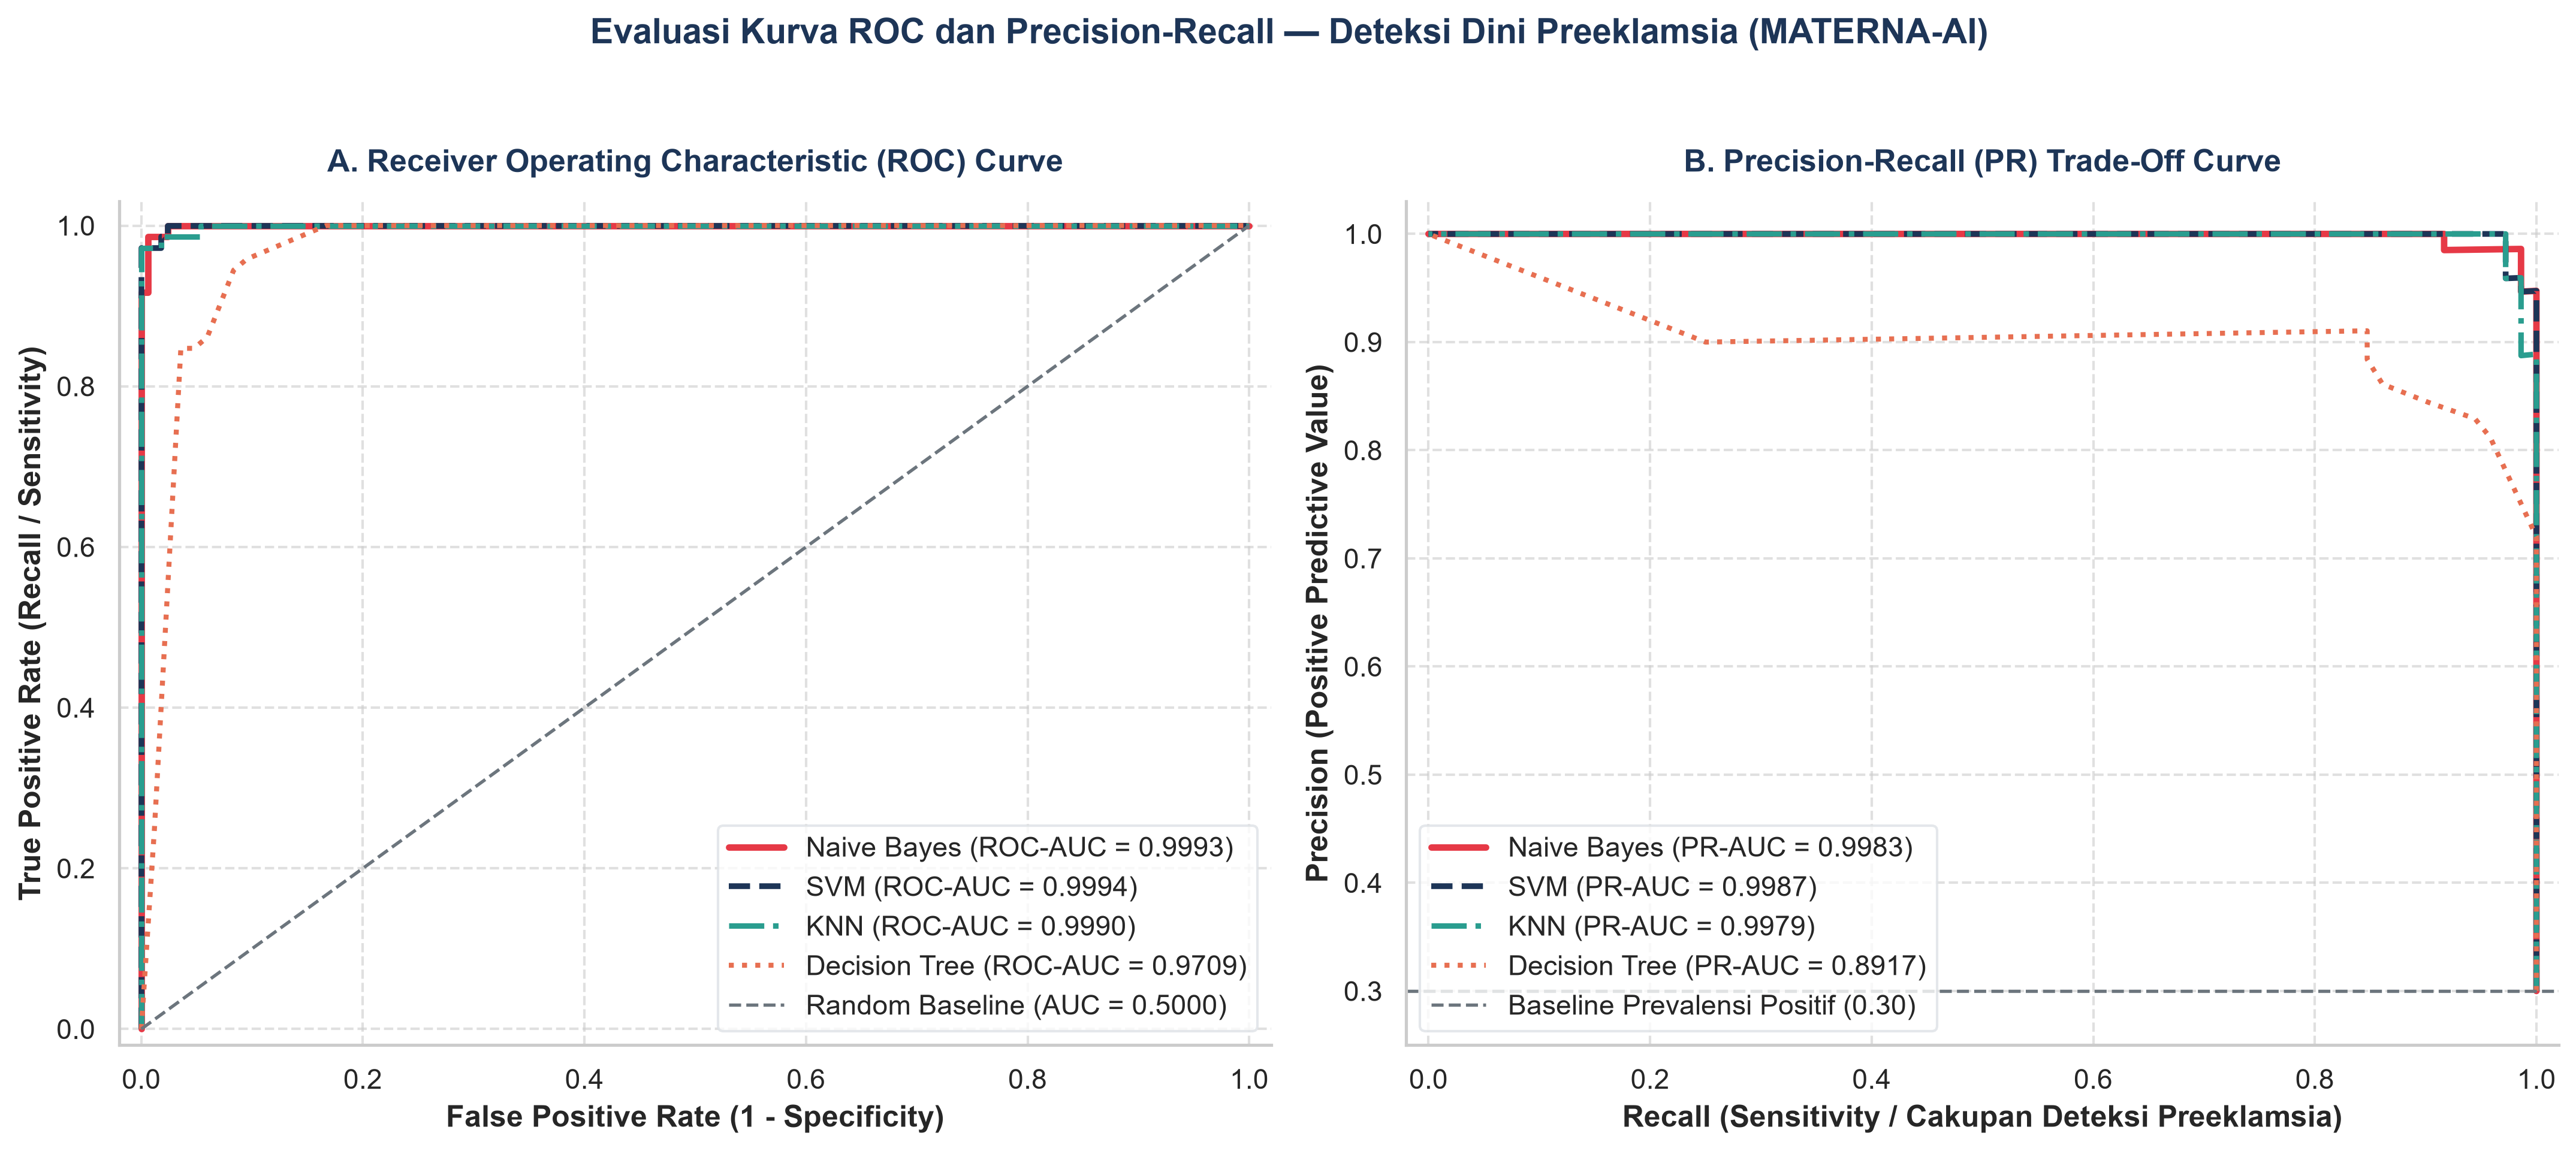

In [ ]:
# 10. ROC Curve & Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.2), dpi=300)
model_styles = {
    'Naive Bayes':   {'color': '#E63946', 'lw': 2.6, 'ls': '-'},
    'SVM':           {'color': '#1D3557', 'lw': 2.3, 'ls': '--'},
    'KNN':           {'color': '#2A9D8F', 'lw': 2.2, 'ls': '-.'},
    'Decision Tree': {'color': '#E76F51', 'lw': 2.0, 'ls': ':'},
}

# Panel Kiri: Kurva ROC
for name in ['Naive Bayes', 'SVM', 'KNN', 'Decision Tree']:
    mdl = loaded_models[name]
    y_prob = mdl.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    st = model_styles[name]
    axes[0].plot(fpr, tpr, color=st['color'], lw=st['lw'], linestyle=st['ls'], label=f'{name} (ROC-AUC = {auc_val:.4f})')

axes[0].plot([0, 1], [0, 1], color='#6C757D', linestyle='--', lw=1.3, label='Random Baseline (AUC = 0.5000)')
axes[0].set_xlim(-0.02, 1.02)
axes[0].set_ylim(-0.02, 1.03)
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', fontweight='bold')
axes[0].set_ylabel('True Positive Rate (Recall / Sensitivity)', fontweight='bold')
axes[0].set_title('A. Receiver Operating Characteristic (ROC) Curve', fontsize=12.5, fontweight='bold', color='#1D3557', pad=12)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#DEE2E6')

# Panel Kanan: Kurva Precision-Recall
pos_rate = y_test.mean()
for name in ['Naive Bayes', 'SVM', 'KNN', 'Decision Tree']:
    mdl = loaded_models[name]
    y_prob = mdl.predict_proba(X_test)[:, 1]
    prec_c, rec_c, _ = precision_recall_curve(y_test, y_prob)
    pr_auc_val = average_precision_score(y_test, y_prob)
    st = model_styles[name]
    axes[1].plot(rec_c, prec_c, color=st['color'], lw=st['lw'], linestyle=st['ls'], label=f'{name} (PR-AUC = {pr_auc_val:.4f})')

axes[1].axhline(pos_rate, color='#6C757D', linestyle='--', lw=1.3, label=f'Baseline Prevalensi Positif ({pos_rate:.2f})')
axes[1].set_xlim(-0.02, 1.02)
axes[1].set_ylim(0.25, 1.03)
axes[1].set_xlabel('Recall (Sensitivity / Cakupan Deteksi Preeklamsia)', fontweight='bold')
axes[1].set_ylabel('Precision (Positive Predictive Value)', fontweight='bold')
axes[1].set_title('B. Precision-Recall (PR) Trade-Off Curve', fontsize=12.5, fontweight='bold', color='#1D3557', pad=12)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(loc='lower left', frameon=True, facecolor='white', edgecolor='#DEE2E6')

sns.despine(top=True, right=True)
plt.suptitle(
    'Evaluasi Kurva ROC dan Precision-Recall — Deteksi Dini Preeklamsia (MATERNA-AI)',
    fontsize=14, fontweight='bold', y=1.03, color='#1D3557'
)
plt.tight_layout()
plt.savefig('reports/10_roc_and_pr_curves.png', dpi=300, bbox_inches='tight')
save_and_sync_figure('10_roc_and_pr_curves.png')
plt.show()

**Interpretasi Klinis — Kurva *ROC* dan *Precision-Recall* (`ROC & PR Curves`):**
- **Kurva ROC (Panel A)** memperlihatkan bahwa lintasan kurva `Naive Bayes` (`AUC = 0.9993`), `SVM` (`AUC = 0.9994`), dan `KNN` (`AUC = 0.9990`) menempel sangat rapat ke sudut kiri atas (*True Positive Rate* mendekati `1.0` pada *False Positive Rate* mendekati `0.0`). Ini menandakan sensitivitas amat tinggi dapat dicapai tanpa mengorbankan spesifisitas.
- **Kurva Precision-Recall (Panel B)** merupakan indikator yang sangat krusial pada dataset klinis dengan kelas tidak seimbang (*30% positif preeklamsia*). Berbeda dengan ROC yang dapat terlihat optimis ketika jumlah *True Negative* besar, kurva PR berfokus penuh pada kinerja deteksi kelas positif. Nilai **PR-AUC** sebesar **`0.9987` (SVM)**, **`0.9983` (Naive Bayes)**, dan **`0.9979` (KNN)** menunjukkan bahwa hingga tingkat *Recall* $> 98\%$, presisi prediksi tetap bertahan di atas $98\%$.
- Fleksibilitas kurva ini memungkinkan klinisi menyesuaikan *operating threshold*: menggunakan ambang batas lebih rendah di **Faskes Primer (Puskesmas/Posyandu)** untuk memaksimalkan *Recall* (jaring pengaman skrining awal), serta ambang terkalibrasi di **RSUD Rujukan** untuk penegakan diagnosis definitif.